# Trabajo del grupo 6, datos de las 5 grandes ligas europeas del fútbol
Alejandro Álvarez Segoviano e Ivo Reguero Ferrer

# 0. Importamos librerías

In [88]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML, display
import numpy as np
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_classif
from scipy.stats import spearmanr, pointbiserialr, mannwhitneyu, chi2_contingency

In [89]:
'''
ruta = Path().resolve().parent
ruta = ruta / "data" / "fulbo.csv"
ruta
''' # Se cambia, quita o deja en funcion de como pida leer los datos, del directorio directo, otra carpeta o etc...

'\nruta = Path().resolve().parent\nruta = ruta / "data" / "fulbo.csv"\nruta\n'

In [90]:
ruta = "fulbo.csv"

# 1. Primer vistazo a los datos y EDA

## 1.1 Mirada inicial

Vamos a comenzar leyendo los datos, observando de cuántas observaciones disponemos, cuántos atributos y de qué naturaleza, previo a la modelización para entender mejor la naturaleza de ellas, cómo se relacionan y si presentan limitaciones o sesgos, para hallar de que tipo son.

In [91]:
df = pd.read_csv(ruta,header=1,index_col="Rk") # para no agrupar por el tipo de variable

In [92]:
df.head()

,Player,Nation,Pos,Squad,Comp,Age,Born,MP,Starts,Min,...,PKatt,CrdY,CrdR,Gls.1,Ast.1,G+A.1,G-PK.1,G+A-PK,Matches,-9999
Rk,,,,,,,,,,,,,,,,,,,,,
1,Brenden Aaronson,us USA,MFFW,Leeds United,eng Premier League,24.0,2000.0,37,30,2449,...,0,3,0,0.15,0.18,0.33,0.15,0.33,Matches,5bc43860
2,Jerome Abbey,eng ENG,MF,Wolves,eng Premier League,15.0,2009.0,1,0,17,...,0,0,0,0.00,0.00,0.00,0.00,0.00,Matches,4f504fcc
3,Zach Abbott,eng ENG,DF,Nottingham,eng Premier League,19.0,2006.0,3,2,164,...,0,0,0,0.00,0.00,0.00,0.00,0.00,Matches,c103921a
4,Jones El-Abdellaoui,ma MAR,MFFW,Celta Vigo,es La Liga,19.0,2006.0,22,4,681,...,0,0,0,0.26,0.00,0.26,0.26,0.26,Matches,29dd3b2e
5,Himad Abdelli,dz ALG,MF,Marseille,fr Ligue 1,25.0,1999.0,8,1,138,...,0,1,0,0.00,0.00,0.00,0.00,0.00,Matches,7978cbf0


In [93]:
print(f"Disponemos de {df.shape[0]} jugadores y {df.shape[1]} atributos.")

Disponemos de 2839 jugadores y 26 atributos.


Esos 27 atributos son los siguientes :

In [94]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2839 entries, 1 to 2839
Data columns (total 26 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Player   2839 non-null   str    
 1   Nation   2836 non-null   str    
 2   Pos      2839 non-null   str    
 3   Squad    2839 non-null   str    
 4   Comp     2839 non-null   str    
 5   Age      2837 non-null   float64
 6   Born     2837 non-null   float64
 7   MP       2839 non-null   int64  
 8   Starts   2839 non-null   int64  
 9   Min      2839 non-null   int64  
 10  90s      2839 non-null   float64
 11  Gls      2839 non-null   int64  
 12  Ast      2839 non-null   int64  
 13  G+A      2839 non-null   int64  
 14  G-PK     2839 non-null   int64  
 15  PK       2839 non-null   int64  
 16  PKatt    2839 non-null   int64  
 17  CrdY     2839 non-null   int64  
 18  CrdR     2839 non-null   int64  
 19  Gls.1    2839 non-null   float64
 20  Ast.1    2839 non-null   float64
 21  G+A.1    2839 non-null   

Algunos atributos tienen nulos, de igual forma cada variable individualmente será revisada después por si hay nulos codificados.

La página web de la que provienen los datos posee un glosario que usaremos para poder explicar qué significa cada dato, en la siguiente sección lo usaremos.

## 1.2 Diccionario De Atributos

In [95]:
diccionario = {
    "Identificación": [
        ("Rk", "Posición en la tabla de FBref (sin valor analítico)"),
        ("Player", "Nombre del jugador"),
        ("Nation", "Nacionalidad (código de 3 letras, p. ej. es ESP)"),
        ("Pos", "Posición: GK, DF, MF, FW; puede combinar varias (MF,FW)"),
        ("Squad", "Club"),
        ("Comp", "Liga / competición"),
        ("Age", "Edad al inicio de la temporada"),
        ("Born", "Año de nacimiento"),
    ],
    "Participación": [
        ("MP", "Partidos jugados"),
        ("Starts", "Partidos como titular"),
        ("Min", "Minutos jugados"),
        ("90s", "Minutos / 90 (denominador de las tasas por 90)"),
    ],
    "Producción ofensiva (totales)": [
        ("Gls", "Goles"),
        ("Ast", "Asistencias"),
        ("G+A", "Goles + asistencias"),
        ("G-PK", "Goles sin contar penaltis"),
        ("PK", "Penaltis marcados"),
        ("PKatt", "Penaltis intentados"),
    ],
    "Disciplina": [
        ("CrdY", "Tarjetas amarillas"),
        ("CrdR", "Tarjetas rojas"),
    ],
    "Por 90 minutos (el sufijo .1 lo añade pandas)": [
        ("Gls.1", "Goles por 90 min"),
        ("Ast.1", "Asistencias por 90 min"),
        ("G+A.1", "Goles + asistencias por 90 min"),
        ("G-PK.1", "Goles sin penalti por 90 min"),
        ("G+A-PK", "(Goles sin penalti + asistencias) por 90 min"),
    ],
    "Otras": [
        ("Matches", "Enlace al detalle partido a partido (sin valor analítico)"),
        ("-9999", "Sin identificar. Hipótesis: ID de jugador; verificar con nunique()"),
    ],
}

FONT = "18px"   # cambia aquí el tamaño

html = f"<div style='font-size:{FONT}'>"
html += "<h2>Diccionario de variables (FBref · Standard Stats)</h2>"
for seccion, filas in diccionario.items():
    html += f"<h3>{seccion}</h3><table style='border-collapse:collapse;width:100%'>"
    html += "<tr><th style='text-align:left;padding:8px;border-bottom:2px solid #888'>Variable</th>"
    html += "<th style='text-align:left;padding:8px;border-bottom:2px solid #888'>Descripción</th></tr>"
    for var, desc in filas:
        html += (f"<tr><td style='padding:8px;border-bottom:1px solid #ccc'><code>{var}</code></td>"
                 f"<td style='padding:8px;border-bottom:1px solid #ccc'>{desc}</td></tr>")
    html += "</table>"

display(HTML(html))

Variable,Descripción
Rk,Posición en la tabla de FBref (sin valor analítico)
Player,Nombre del jugador
Nation,"Nacionalidad (código de 3 letras, p. ej. es ESP)"
Pos,"Posición: GK, DF, MF, FW; puede combinar varias (MF,FW)"
Squad,Club
Comp,Liga / competición
Age,Edad al inicio de la temporada
Born,Año de nacimiento
Variable,Descripción
MP,Partidos jugados


## 1.3 Calidad del dato

En este apartado vamos a evaluar la calidad de los datos, hablando en castellano esto es asegurarnos los datos sean coherentes, no estén duplicados (principalmente para evitar leakage), tratar posibles nulos entre otras situaciones.

Se comenzará analizando la presencia de nulos en el dataset

In [96]:
df.isnull().sum()

Player     0
Nation     3
Pos        0
Squad      0
Comp       0
Age        2
Born       2
MP         0
Starts     0
Min        0
90s        0
Gls        0
Ast        0
G+A        0
G-PK       0
PK         0
PKatt      0
CrdY       0
CrdR       0
Gls.1      0
Ast.1      0
G+A.1      0
G-PK.1     0
G+A-PK     0
Matches    0
-9999      0
dtype: int64

Se presencian nulos en las variables Age, Born y Nation

In [97]:
df[df["Nation"].isnull()]

,Player,Nation,Pos,Squad,Comp,Age,Born,MP,Starts,Min,...,PKatt,CrdY,CrdR,Gls.1,Ast.1,G+A.1,G-PK.1,G+A-PK,Matches,-9999
Rk,,,,,,,,,,,,,,,,,,,,,
1699,Nathan Mbala,NaN,MFFW,Metz,fr Ligue 1,17.0,2008.0,13,4,441,...,0,0,0,0.41,0.41,0.82,0.41,0.82,Matches,42754695
2005,Luis Orejuela,NaN,DF,Mallorca,es La Liga,NaN,NaN,1,1,90,...,0,0,0,0.00,0.00,0.00,0.00,0.00,Matches,18e70be1
2631,Yael Trepy,NaN,FW,Cagliari,it Serie A,NaN,NaN,8,0,91,...,0,0,0,0.99,0.00,0.99,0.99,0.99,Matches,20c36c00


Apreciamos son tres casos a priori aislados, a excepción de los casos de Luis Orejuela y Yael Trepy, donde la falta de la fecha de nacimiento y edad tiene sentido, ya que a partir de una se podría estimar un proxy de la otra, sin embargo al carecer de ambas esa información se pierde

Debido a que son solo tres filas con faltantes la información faltante ha sido buscada y va a ser imputada.

Para el caso de Nathan Mbala este nulo tiene un significado, dado que al inspeccionar en internet hay informacion que se contradice, por una parte algunas páginas le atribuyen nacionalidad francesa mientras que otras le atribuyen nacionalidad de la república del congo, incluso llegan a contradecirse de en que lugar nació, por lo que se va a dejar como nulo para no introducir información no verificada

In [98]:
df.loc[df['Player'] == 'Luis Orejuela', ['Nation', 'Age', 'Born']] = ['es ESP', 18, 2007]
df.loc[df['Player'] == 'Yael Trepy', ['Nation', 'Age', 'Born']] = ['fr FRA', 19, 2006]

In [99]:
df.isnull().sum()

Player     0
Nation     1
Pos        0
Squad      0
Comp       0
Age        0
Born       0
MP         0
Starts     0
Min        0
90s        0
Gls        0
Ast        0
G+A        0
G-PK       0
PK         0
PKatt      0
CrdY       0
CrdR       0
Gls.1      0
Ast.1      0
G+A.1      0
G-PK.1     0
G+A-PK     0
Matches    0
-9999      0
dtype: int64

Una vez acabados con los nulos, se pasa a investigar la presencia de duplicados

In [100]:
# Filas completamente idénticas
print("Filas duplicadas exactas:", df.duplicated().sum())

# Mismo nombre pero ID distinto (posibles homónimos)
por_nombre = df.groupby('Player')['-9999'].nunique()
homonimos = por_nombre[por_nombre > 1]
print("Nombres compartidos por IDs distintos:", len(homonimos))


Filas duplicadas exactas: 0
Nombres compartidos por IDs distintos: 4


¿Cuántos de ellos son la misma persona y cuantos son solo el mismo nombre?

In [101]:
equipos = df.groupby('-9999')['Squad'].nunique()
ids_traspasados = equipos[equipos > 1].index

traspasados = (df[df['-9999'].isin(ids_traspasados)]
               .sort_values(['-9999', 'Min'], ascending=[True, False]))

print("Jugadores en más de un equipo:", len(ids_traspasados))
print("Filas implicadas:", len(traspasados))

resumen = (traspasados.groupby(['-9999', 'Player'])
           .apply(lambda g: ' → '.join(f"{s} ({m} min)" for s, m in zip(g['Squad'], g['Min'])))
           .reset_index(name='equipos'))
resumen

Jugadores en más de un equipo: 148
Filas implicadas: 296


,-9999,Player,equipos
0,004d185e,Tete Morente,Elche (929 min) → Lecce (859 min)
1,0400dd2f,Badredine Bouanani,Stuttgart (463 min) → Nice (93 min)
2,0545a08e,Walid Cheddira,Lecce (1000 min) → Sassuolo (221 min)
3,0562b7f1,Odsonne Édouard,Lens (1796 min) → Crystal Palace (3 min)
4,08391d76,Leonidas Stergiou,Heidenheim (206 min) → Stuttgart (1 min)
...,...,...,...
143,fb495bb8,Matt O'Riley,Marseille (741 min) → Brighton (204 min)
144,fbb270b2,Cole Campbell,Hoffenheim (79 min) → Dortmund (17 min)
145,fc076f78,Luca Koleosho,Paris FC (554 min) → Espanyol (63 min)
146,fe012aca,Jeremie Boga,Juventus (679 min) → Nice (646 min)


Vamos a asegurarnos antes de manipular los datos que no tenemos casos en que los repetidos no pertenezcan a traspasos

In [102]:
ids_repetidos = set(df.loc[df.duplicated('-9999', keep=False), '-9999'])
ids_traspasados = set(equipos[equipos > 1].index)
print(ids_repetidos == ids_traspasados)

True


Vamos a compactar la información de los jugadores en una única observación, principalmente para evitar fuga de información. Vamos a realizarlo de la forma : Consolidar en una misma información las variables principales, calculando las derivadas una vez se ha consolidado todo y manteniendo en una nueva variable que se ha dado un traspaso, dado que puede ser relevante más tarde

In [103]:
d = df.drop(columns=['Matches'], errors='ignore')

# Separar id único de id repetido
dup = d.duplicated('-9999', keep=False)
unicos = d[~dup].copy()
repetidos = d[dup].sort_values('Min', ascending=False)   # 'first' = club con más minutos

# solo los repetidos
sumas = ['MP', 'Starts', 'Min', '90s', 'Gls', 'Ast', 'G+A',
         'G-PK', 'PK', 'PKatt', 'CrdY', 'CrdR']
primeros = ['Player', 'Nation', 'Born', 'Age', 'Pos', 'Squad', 'Comp']
agg = {**{c: 'sum' for c in sumas}, **{c: 'first' for c in primeros}}

cons = repetidos.groupby('-9999', as_index=False).agg(agg)

# marca de traspaso
g = repetidos.groupby('-9999')['Squad']
cons['n_clubes'] = cons['-9999'].map(g.nunique())
cons['equipos'] = cons['-9999'].map(g.agg(' | '.join))
cons['traspaso'] = cons['n_clubes'] > 1

# recalcular las tasas por 90 solo en las consolidadas
v = cons['90s'] > 0
cons['Gls.1']   = (cons['Gls'] / cons['90s']).where(v)
cons['Ast.1']   = (cons['Ast'] / cons['90s']).where(v)
cons['G+A.1']   = (cons['G+A'] / cons['90s']).where(v)
cons['G-PK.1']  = (cons['G-PK'] / cons['90s']).where(v)
cons['G+A-PK']  = ((cons['G-PK'] + cons['Ast']) / cons['90s']).where(v)

# las filas únicas reciben las mismas columnas nuevas
unicos['n_clubes'] = 1
unicos['traspaso'] = False

df_nodup = pd.concat([unicos, cons[unicos.columns]], ignore_index=True)

In [104]:
print(len(df_nodup) == d['-9999'].nunique())          # True -> una fila por jugador
print(df_nodup['-9999'].duplicated().sum())           # Deberia dar 0
print(df_nodup['Min'].sum() == d['Min'].sum())        # True -> no se pierden minutos
print(df_nodup['Gls'].sum() == d['Gls'].sum())        # True -> ni goles
print(df_nodup['traspaso'].sum())                     # debe coincidir con tu recuento de traspasados
print(len(unicos) == (~df_nodup['traspaso']).sum())   # True -> las únicas no se han tocado


True
0
True
True
148
True


## 1.3 Borrando casos especiales y excluyendo variables

A partir de este punto, sabemos un poco lo que queremos hacer con nuestra base de datos (Diferenciar delanteros del resto) ya que las únicas estadísticas de partido que tenemos son los goles y asistencias, estadísticas ofensivas que no permiten diferenciar a jugadores defensivos de porteros, por ejemplo.

Vamos a querer evitar que aparezcan dos tipos de outliers, los porteros y los jugadores de cantera. Los porteros, exceptuando unos pocos casos, no marcan, y los jugadores de cantera (y los jugadores muy revulsivos) apenas juegan. El problema con los primeros es que no son jugadores de campo, así que no van a tener apenas estadísticas ofensivas y van a ser muy fácilmente clasificables, y el de los segundos es que juegan poco, y eso puede causar outliers extremos. Ejemplo, un canterano que marca un gol en un partido y no vuelve a jugar podría tener un goles por 90 de 3, lo cual es un outlier extremo.

In [105]:
df_canteranos = df_nodup[df_nodup['Min'] < 90]
boxplot = df_canteranos.boxplot(column=['Gls', 'Gls.1'])

En la representación de arriba, vemos como un jugador que no jugó mucho tiene una media de más de 8 goles cada 90 minutos, es un atípico enorme. En general, es atípico que marquen goles.

Vamos a borrar las filas que tienen pos = GK y las que han jugado menos de 90 minutos:

In [106]:
df_filtrado = df_nodup[(df_nodup['Pos'] != 'GK') & (df_nodup['Min'] >= 90)]
print(f"Quedan {df_filtrado.shape[0]} jugadores después del filtrado.")

Quedan 2181 jugadores después del filtrado.


Lo mejor sería tratar a cada fila como si fuese un jugador distinto. ¿Por qué? Porque cambiar de equipo puede cambiar tu posición habitual, tu liga (en la Bundesliga se marca muchas más veces por partido, por ejemplo) y tu estado de ánimo (un jugador descontento cambia de club y empieza a rendir en su nuevo club). No queremos, entonces, conocer al jugador y vamos a borrar todo lo que lo identifique.

Tras haber sido transformado a un CSV, hemos perdido información a la que podríamos acceder desde la página web: enlaces en el nombre de los jugadores que nos permitían acceder a un perfil de la página del jugador con más información, lo cual ocurre también con la selección, el equipo y la liga, y la razón por la que se ha escogido esa nacionalidad para el jugador.

Otro dato que perdemos es el enlace que te conecta a los partidos que ha jugado en esa temporada el jugador. Si quisiésemos recuperar el enlace, en el caso de Brenden Aaronson, tendríamos que reconstruirlo usando el atributo de la última columna, la temporada que queremos mirar (en nuestro caso 2025-2026) y su nombre separado por guiones para poder ver todos los partidos que jugó durante la temporada. (https://fbref.com/en/players/5bc43860/matchlogs/2025-2026/summary/Brenden-Aaronson-Match-Logs)

Ahora que sabemos que estas columnas no nos sirven para modelar, podemos borrar las columnas _Matches_ y _-9999_.

**Vamos a borrar esas dos columnas:**

In [107]:
df_filtrado = df_filtrado.drop(columns=['-9999'])
df_filtrado.head()

,Player,Nation,Pos,Squad,Comp,Age,Born,MP,Starts,Min,...,PKatt,CrdY,CrdR,Gls.1,Ast.1,G+A.1,G-PK.1,G+A-PK,n_clubes,traspaso
0,Brenden Aaronson,us USA,MFFW,Leeds United,eng Premier League,24.0,2000.0,37,30,2449,...,0,3,0,0.15,0.18,0.33,0.15,0.33,1,False
2,Zach Abbott,eng ENG,DF,Nottingham,eng Premier League,19.0,2006.0,3,2,164,...,0,0,0,0.00,0.00,0.00,0.00,0.00,1,False
3,Jones El-Abdellaoui,ma MAR,MFFW,Celta Vigo,es La Liga,19.0,2006.0,22,4,681,...,0,0,0,0.26,0.00,0.26,0.26,0.26,1,False
4,Ali Abdi,tn TUN,MFDF,Nice,fr Ligue 1,31.0,1993.0,22,13,1187,...,0,4,1,0.23,0.00,0.23,0.23,0.23,1,False
5,Salis Abdul Samed,gh GHA,MF,Nice,fr Ligue 1,25.0,2000.0,18,12,911,...,0,3,0,0.00,0.00,0.00,0.00,0.00,1,False


Más cosas que no queremos son el nombre, la nación y el equipo. El nombre no lo queremos porque identifica al jugador, y la nación y el equipo nos forzaría a añadir muchísimas variables dummy (~110 naciones y 96 equipos distintos). No queremos sufrir de maldición de la dimensionalidad así que vamos a excluirlas también.

**Borremos otras tres columnas:**

In [108]:
df_filtrado = df_filtrado.drop(columns=['Player', 'Nation', 'Squad'])
df_filtrado.head()

,Pos,Comp,Age,Born,MP,Starts,Min,90s,Gls,Ast,...,PKatt,CrdY,CrdR,Gls.1,Ast.1,G+A.1,G-PK.1,G+A-PK,n_clubes,traspaso
0,MFFW,eng Premier League,24.0,2000.0,37,30,2449,27.2,4,5,...,0,3,0,0.15,0.18,0.33,0.15,0.33,1,False
2,DF,eng Premier League,19.0,2006.0,3,2,164,1.8,0,0,...,0,0,0,0.00,0.00,0.00,0.00,0.00,1,False
3,MFFW,es La Liga,19.0,2006.0,22,4,681,7.6,2,0,...,0,0,0,0.26,0.00,0.26,0.26,0.26,1,False
4,MFDF,fr Ligue 1,31.0,1993.0,22,13,1187,13.2,3,0,...,0,4,1,0.23,0.00,0.23,0.23,0.23,1,False
5,MF,fr Ligue 1,25.0,2000.0,18,12,911,10.1,0,0,...,0,3,0,0.00,0.00,0.00,0.00,0.00,1,False


Cambiemos el formato con el que guardamos la *Pos* y la *Comp*:

En el caso de *Comp*, vamos a hacer *one hot encoding* porque queremos saber a que liga pertenece cada jugador, y queremos guardarlo en algo que no sea un string.

En el de *Pos* lo que haremos es convertirla en una binaria, queremos saber si el jugador juega de delantero (tiene FW o alguna combinación que lo incluya) o no. Arriba hemos visto que los que contienen *foward* son FW, MFFW, FWMF y DFFW, serán 1. El resto serán 0.

Hagamos las transformaciones:

In [109]:
df_filtrado = pd.get_dummies(df_filtrado, columns=['Comp'], dtype=int, drop_first=True) # perdemos bundesliga
# pero si no perteneces a ninguna de las cuatro ligas representadas por el dummy, eres de la bundesliga
# no pierdes info ni eres redundante asi
df_filtrado.head()

,Pos,Age,Born,MP,Starts,Min,90s,Gls,Ast,G+A,...,Ast.1,G+A.1,G-PK.1,G+A-PK,n_clubes,traspaso,Comp_eng Premier League,Comp_es La Liga,Comp_fr Ligue 1,Comp_it Serie A
0,MFFW,24.0,2000.0,37,30,2449,27.2,4,5,9,...,0.18,0.33,0.15,0.33,1,False,1,0,0,0
2,DF,19.0,2006.0,3,2,164,1.8,0,0,0,...,0.00,0.00,0.00,0.00,1,False,1,0,0,0
3,MFFW,19.0,2006.0,22,4,681,7.6,2,0,2,...,0.00,0.26,0.26,0.26,1,False,0,1,0,0
4,MFDF,31.0,1993.0,22,13,1187,13.2,3,0,3,...,0.00,0.23,0.23,0.23,1,False,0,0,1,0
5,MF,25.0,2000.0,18,12,911,10.1,0,0,0,...,0.00,0.00,0.00,0.00,1,False,0,0,1,0


In [110]:
df_filtrado['Rol_Ofensivo'] = df_filtrado['Pos'].str.contains('FW').astype(int)
display(df_filtrado[['Pos', 'Rol_Ofensivo']].value_counts()) # comprobando si estan bien asignados
# los tres delantero-defensas han sido excluidos por ser canteranos o por valores faltantes, una de dos
print(df_filtrado['Rol_Ofensivo'].value_counts()) # veamos cuantos tenemos de cada tipo

Pos   Rol_Ofensivo
MF    0               739
DF    0               608
FW    1               274
MFFW  1               207
DFMF  0               126
FWMF  1               114
MFDF  0               113
Name: count, dtype: int64

Rol_Ofensivo
0    1586
1     595
Name: count, dtype: int64


In [111]:
# ahora que hemos visto que esta bien, borramos la variable pos
df_filtrado = df_filtrado.drop(columns=['Pos'])

Por último, tenemos que pensar cuáles de las variables redundantes queremos borrar. Quitaremos cuatro selectas: *Born*, *90s*, *G+A* y *G+A.1*, porque son combinaciones lineales exactas. Otras, que se van a conservar, también lo son, pero las conservamos para ver cuál preferimos después de hacer otro filtrado o una regularización.

In [112]:
# df_filtrado = df_filtrado.drop(columns=['Born', '90s', 'G+A', 'G+A.1']) Provisional hasta acabar eda

Nuestra base de datos termina quedando así, después de todo esto:

In [113]:
df_filtrado.head()

,Age,Born,MP,Starts,Min,90s,Gls,Ast,G+A,G-PK,...,G+A.1,G-PK.1,G+A-PK,n_clubes,traspaso,Comp_eng Premier League,Comp_es La Liga,Comp_fr Ligue 1,Comp_it Serie A,Rol_Ofensivo
0,24.0,2000.0,37,30,2449,27.2,4,5,9,4,...,0.33,0.15,0.33,1,False,1,0,0,0,1
2,19.0,2006.0,3,2,164,1.8,0,0,0,0,...,0.00,0.00,0.00,1,False,1,0,0,0,0
3,19.0,2006.0,22,4,681,7.6,2,0,2,2,...,0.26,0.26,0.26,1,False,0,1,0,0,1
4,31.0,1993.0,22,13,1187,13.2,3,0,3,3,...,0.23,0.23,0.23,1,False,0,0,1,0,0
5,25.0,2000.0,18,12,911,10.1,0,0,0,0,...,0.00,0.00,0.00,1,False,0,0,1,0,0


In [114]:
print(f"Disponemos de {df_filtrado.shape[0]} jugadores y {df_filtrado.shape[1]} atributos.")

Disponemos de 2181 jugadores y 26 atributos.


Hemos reducido bastantes dimensiones, teniendo en cuenta que luego vamos a quitar más.

In [115]:
cols = ["Comp_eng Premier League","Comp_es La Liga","Comp_fr Ligue 1","Comp_it Serie A","Rol_Ofensivo","traspaso"]
df_filtrado[cols] = df_filtrado[cols].astype('category')

## 1.5 EDA

Estructuramos el análisis exploratorio en cinco pasos sencillos, trabajando siempre sobre la partición de entrenamiento para evitar fuga de información:
1. **1.5.1 Partición Train / Test** y balance de la variable objetivo.
2. **1.5.2 Resumen general y función auxiliar** para inspeccionar cada variable y sus *outliers*.
3. **1.5.3 Análisis variable por variable** (viendo en código si los *outliers* son ruido o señal válida y qué aporta cada una al modelado).
4. **1.5.4 Correlaciones (Pearson y Spearman) e Información Mutua** con la variable objetivo.
5. **1.5.5 Limpieza final post-EDA** de las variables redundantes exactas en `X_train` y `X_test`.

### 1.5.1 Partición Train / Test y Balance de Clases

Separamos primero el conjunto de datos en **Train (80%)** y **Test (20%)** de forma estratificada sobre `Rol_Ofensivo`. El conjunto de `Test` se reserva intacto para la evaluación final y todo el EDA se realiza exclusivamente sobre `Train` (donde aplicaremos validación cruzada durante el modelado).

,n,Clase 0 (No Ofensivo),Clase 1 (Ofensivo),% Ofensivo,Ratio 0:1,Nulos
Total,2181,1586,595,27.28,2.67,0
Train (80%),1744,1268,476,27.29,2.66,0
Test (20%),437,318,119,27.23,2.67,0


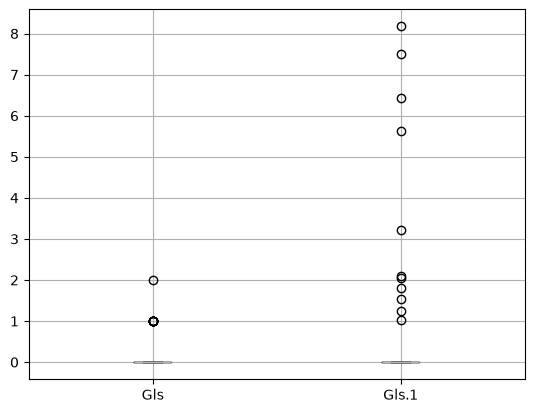

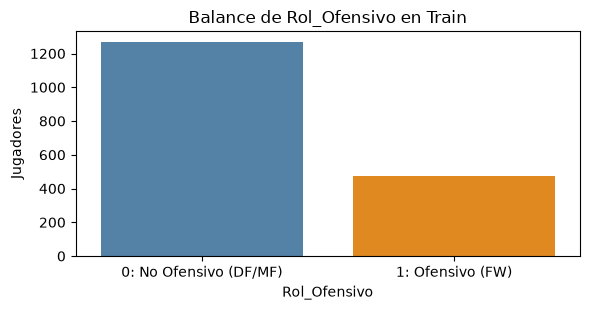

In [116]:
y = df_filtrado['Rol_Ofensivo'].astype(int)
X = df_filtrado.drop(columns=['Rol_Ofensivo']).copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

train_df = X_train.copy()
train_df['Rol_Ofensivo'] = y_train

resumen_split = pd.DataFrame({
    'n': [len(df_filtrado), len(X_train), len(X_test)],
    'Clase 0 (No Ofensivo)': [(y == 0).sum(), (y_train == 0).sum(), (y_test == 0).sum()],
    'Clase 1 (Ofensivo)': [(y == 1).sum(), (y_train == 1).sum(), (y_test == 1).sum()],
    '% Ofensivo': [y.mean() * 100, y_train.mean() * 100, y_test.mean() * 100],
    'Ratio 0:1': [(y == 0).sum() / (y == 1).sum(), (y_train == 0).sum() / (y_train == 1).sum(), (y_test == 0).sum() / (y_test == 1).sum()],
    'Nulos': [df_filtrado.isna().sum().sum(), X_train.isna().sum().sum(), X_test.isna().sum().sum()]
}, index=['Total', 'Train (80%)', 'Test (20%)']).round(2)
display(resumen_split)

fig, ax = plt.subplots(figsize=(6, 3.2))
sns.countplot(x=y_train, hue=y_train, palette=['steelblue', 'darkorange'], legend=False, ax=ax)
ax.set_xticks([0, 1])
ax.set_xticklabels(['0: No Ofensivo (DF/MF)', '1: Ofensivo (FW)'])
ax.set_title('Balance de Rol_Ofensivo en Train')
ax.set_ylabel('Jugadores')
plt.tight_layout()
plt.show()

La partición estratificada mantiene la misma proporción de clases en `Train` y `Test` sin valores nulos. Al existir desbalanceo hacia la clase `0` (No Ofensivo), un modelo que predijera siempre la clase mayoritaria acertaría la mayoría de los casos sin detectar delanteros; por ello en el modelado utilizaremos **Balanced Accuracy**, **F1-Score** y **ROC-AUC** además del *Accuracy*.

### 1.5.2 Resumen General y Función Auxiliar

Mostramos primero los estadísticos descriptivos de `X_train` y definimos una función sencilla (`analizar_variable`) para inspeccionar cada variable sin repetir código. Para no exagerar conclusiones a partir de diferencias pequeñas (que en una muestra de este tamaño o en subgrupos reducidos pueden deberse a simple variabilidad estadística), la función muestra:
1. Estadísticos por clase (`mean`, `std`, `median`, `IQR`) y su correlación lineal (`r_pb`) con `Rol_Ofensivo`, para comparar la diferencia entre clases frente a la dispersión real de los datos.
2. Resumen de *outliers* según el criterio IQR y el tamaño (`N`) de cada subgrupo.
3. Los 5 jugadores con valores más altos en `Train` y las gráficas de distribución y boxplot por clase, a partir de los cuales planteamos hipótesis sencillas para el modelado.

In [117]:
num_cols = X_train.select_dtypes(include='number').columns.tolist()
cat_cols = X_train.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()

# Tabla descriptiva general sobre Train
resumen_general = X_train[num_cols].describe().T
resumen_general['skew'] = X_train[num_cols].skew()
resumen_general['% ceros'] = (X_train[num_cols] == 0).mean() * 100
display(resumen_general.round(2))

# Metadatos SOLO de Train para identificar a qué jugadores corresponden los outliers
info_train = df_nodup.loc[X_train.index, ['Player', 'Pos', 'Squad', 'Min']].copy()
info_train['Rol_Ofensivo'] = y_train


def analizar_variable(col, es_tasa=False):
    s = train_df[col]
    q1, q3 = s.quantile([0.25, 0.75])
    ub = q3 + 1.5 * (q3 - q1)
    outliers = train_df[s > ub]
    r_pb, _ = pointbiserialr(y_train, s)

    # 1. Estadísticos por clase y correlación con el target
    por_clase = train_df.groupby('Rol_Ofensivo')[col].agg(
        ['count', 'mean', 'std', 'median', lambda x: x.quantile(0.75) - x.quantile(0.25)]
    ).rename(columns={'<lambda_0>': 'IQR'}).round(2)
    por_clase['corr_target'] = round(r_pb, 3)
    display(por_clase)

    # 2. Resumen de outliers IQR
    fila_out = {
        'Variable': col,
        'Umbral IQR': round(ub, 2),
        'N Outliers (>UB)': len(outliers),
        '% Muestra': round(len(outliers) / len(train_df) * 100, 1),
        '% Ofensivos en Outliers': round(outliers['Rol_Ofensivo'].mean() * 100, 1) if len(outliers) else np.nan,
        '% Ofensivos Base': round(y_train.mean() * 100, 1)
    }
    if es_tasa and len(outliers) > 0:
        pocos_min = outliers[outliers['Min'] < 270]
        muchos_min = outliers[outliers['Min'] >= 270]
        fila_out['N (Min<270)'] = len(pocos_min)
        fila_out['% Ofens (Min<270)'] = round(pocos_min['Rol_Ofensivo'].mean() * 100, 1) if len(pocos_min) else np.nan
        fila_out['N (Min>=270)'] = len(muchos_min)
        fila_out['% Ofens (Min>=270)'] = round(muchos_min['Rol_Ofensivo'].mean() * 100, 1) if len(muchos_min) else np.nan
    display(pd.DataFrame([fila_out]))

    # 3. Top 5 valores más altos en Train
    display(info_train.assign(**{col: s}).nlargest(5, col)[['Player', 'Pos', 'Rol_Ofensivo', 'Squad', 'Min', col]])

    # 4. Gráficos (distribución y boxplot por clase)
    es_discreta = s.nunique() <= 15
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
    sns.histplot(
        data=train_df, x=col, hue='Rol_Ofensivo',
        discrete=es_discreta, kde=(not es_discreta),
        stat=('probability' if es_discreta else 'density'),
        common_norm=False, palette=['steelblue', 'darkorange'], ax=ax[0]
    )
    ax[0].set_title(f'Distribución de {col} por clase')

    sns.boxplot(
        data=train_df, x='Rol_Ofensivo', y=col, hue='Rol_Ofensivo',
        palette=['steelblue', 'darkorange'], legend=False, ax=ax[1]
    )
    ax[1].set_title(f'Boxplot de {col} por clase')
    plt.tight_layout()
    plt.show()

,count,mean,std,min,25%,50%,75%,max,skew,% ceros
Age,1744.0,25.12,4.36,15.0,22.00,25.00,28.00,41.00,0.40,0.00
Born,1744.0,1999.52,4.37,1983.0,1997.00,2000.00,2003.00,2009.00,-0.41,0.00
MP,1744.0,22.86,9.44,1.0,15.00,25.00,31.00,39.00,-0.43,0.00
Starts,1744.0,15.95,10.20,0.0,7.00,15.00,24.00,38.00,0.21,1.72
Min,1744.0,1427.58,857.71,90.0,677.75,1362.00,2099.50,3420.00,0.23,0.00
90s,1744.0,15.86,9.53,1.0,7.50,15.15,23.30,38.00,0.23,0.00
Gls,1744.0,2.13,3.18,0.0,0.00,1.00,3.00,36.00,2.92,37.21
Ast,1744.0,1.50,1.97,0.0,0.00,1.00,2.00,21.00,2.64,39.68
G+A,1744.0,3.63,4.36,0.0,1.00,2.00,5.00,41.00,2.31,22.08
G-PK,1744.0,1.93,2.76,0.0,0.00,1.00,3.00,26.00,2.55,37.96


### 1.5.3 Análisis Variable por Variable

Inspeccionamos cada variable de `X_train` individualmente. Las variables que son copias exactas (`Born`, `90s`, `G+A`, `G+A.1`, `n_clubes`) se comprueban en código junto a su variable principal para no duplicar gráficos y se eliminan al final del EDA.

#### 1.5.3.1 `Age` (Edad) *(y `Born`)*

,count,mean,std,median,r_pb,p_valor
Rol_Ofensivo,,,,,,
0,1268,25.20,4.35,25.0,-0.033,1.73e-01
1,476,24.88,4.38,25.0,-0.033,1.73e-01


,Variable,Umbral IQR,N Outliers (>UB),% Muestra,% Ofensivos en Outliers,% Ofensivos Base
0,Age,37.0,12,0.7,50.0,27.3


,Player,Pos,Rol_Ofensivo,Squad,Min,Age
582,Dante,DF,0,Nice,849,41.0
724,Edin Džeko,FW,1,Fiorentina,244,39.0
1591,Luka Modrić,MF,0,Milan,2811,39.0
1571,James Milner,MF,0,Brighton,784,39.0
66,Raúl Albiol,DF,0,Pisa,500,39.0


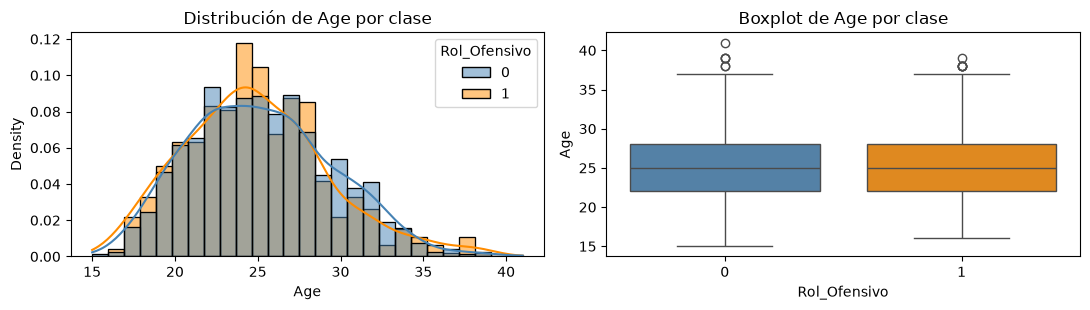

Correlación de Pearson entre Age y Born: -0.994


In [118]:
# 1.5.3.1 Age (y comprobación de redundancia con Born)
analizar_variable('Age')
print('Correlación de Pearson entre Age y Born:', round(X_train['Age'].corr(X_train['Born']), 4))

**Interpretación (`Age` y `Born`):** La varianza explicada (`r² (%)`) es prácticamente nula y no es significativa. Los pocos *outliers* superiores corresponden a jugadores veteranos reales (datos válidos), pero al ser un subgrupo tan reducido cualquier diferencia de proporción entre clases en esa cola se debe a **variabilidad muestral**. **Hipótesis para el modelado:** `Age` no aportará capacidad discriminativa y debería ser anulada por la regularización $L_1$ o descartada por el *wrapper*; `Born` se elimina por redundancia lineal con `Age`.

#### 1.5.3.2 `MP` (Partidos disputados)

,count,mean,std,median,r_pb,p_valor
Rol_Ofensivo,,,,,,
0,1268,22.57,9.59,24.0,0.05,3.73e-02
1,476,23.63,8.98,26.0,0.05,3.73e-02


,Variable,Umbral IQR,N Outliers (>UB),% Muestra,% Ofensivos en Outliers,% Ofensivos Base
0,MP,55.0,0,0.0,NaN,27.3


,Player,Pos,Rol_Ofensivo,Squad,Min,MP
2556,Donyell Malen,FW,1,Roma,2123,39
1584,Tyrick Mitchell,MF,0,Crystal Palace,3251,38
330,Jarrod Bowen,MFFW,1,West Ham,3403,38
880,James Garner,MFDF,0,Everton,3413,38
1696,Victor Nelsson,DF,0,Hellas Verona,3315,38


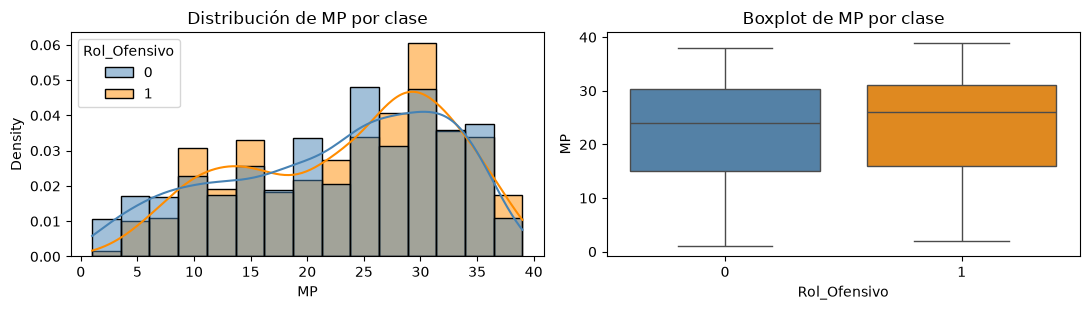

Jugadores con más de 38 partidos (por traspaso invernal entre calendarios):


,Player,Pos,Squad,Min,Rol_Ofensivo,MP,traspaso
2556,Donyell Malen,FW,Roma,2123,1,39,True


In [119]:
# 1.5.3.2 MP (Partidos disputados)
analizar_variable('MP')
print('Jugadores con más de 38 partidos (por traspaso invernal entre calendarios):')
display(info_train.assign(MP=X_train['MP'], traspaso=X_train['traspaso'])[X_train['MP'] > 38])

**Interpretación (`MP`):** Las distribuciones y los boxplots de ambas clases se solapan casi por completo y la correlación con `Rol_Ofensivo` es cercana a cero; la mínima diferencia entre medianas es despreciable frente a la dispersión de la variable y entra dentro de la **variabilidad estadística**. El único caso con más de 38 partidos corresponde a un jugador traspasado en invierno entre calendarios desfasados (dato válido, no error). **Hipótesis para el modelado:** `MP` por sí sola no discrimina; su único interés es comprobar si combinada con `Starts` o `Min` ayuda a reflejar que los atacantes entran más veces como suplentes.

#### 1.5.3.3 `Starts` (Partidos como titular)

,count,mean,std,median,r_pb,p_valor
Rol_Ofensivo,,,,,,
0,1268,16.64,10.41,16.0,-0.11,3.74e-06
1,476,14.11,9.38,13.0,-0.11,3.74e-06


,Variable,Umbral IQR,N Outliers (>UB),% Muestra,% Ofensivos en Outliers,% Ofensivos Base
0,Starts,49.5,0,0.0,NaN,27.3


,Player,Pos,Rol_Ofensivo,Squad,Min,Starts
330,Jarrod Bowen,MFFW,1,West Ham,3403,38
880,James Garner,MFDF,0,Everton,3413,38
2359,Adrien Truffert,DF,0,Bournemouth,3379,38
2394,Virgil van Dijk,DF,0,Liverpool,3420,38
1170,Pierre Kalulu,DFMF,0,Juventus,3281,37


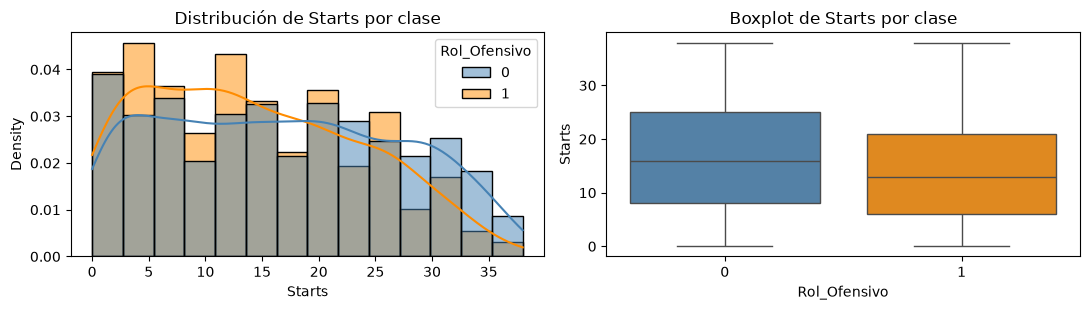

Separación del cociente Starts / MP (tasa de titularidad):


,mean,median,r_pb,p_valor
Rol_Ofensivo,,,,
0,0.69,0.75,-0.235,2.17e-23
1,0.54,0.57,-0.235,2.17e-23


In [120]:
# 1.5.3.3 Starts (Titularidades) y comprobación de la proporción Starts / MP
analizar_variable('Starts')

ratio_titular = X_train['Starts'] / X_train['MP']
r_ratio, _ = pointbiserialr(y_train, ratio_titular)
resumen_ratio = train_df.assign(Starts_MP=ratio_titular).groupby('Rol_Ofensivo')['Starts_MP'].agg(['mean', 'std', 'median']).round(2)
resumen_ratio['corr_target'] = round(r_ratio, 3)
print('Separación del cociente Starts / MP (tasa de titularidad):')
display(resumen_ratio)

**Interpretación (`Starts`):** No presenta *outliers*, pero los boxplots muestran un solapamiento enorme entre clases y la correlación con `Rol_Ofensivo` es baja (la ligera diferencia de medianas es pequeña comparada con la desviación típica de la variable). Al calcular el cociente `Starts / MP` la correlación negativa aumenta algo, aunque sigue habiendo mucho solapamiento porque también existen defensas y medios suplentes. **Hipótesis para el modelado:** por sí sola tiene muy poco peso predictivo; en la Sección III comprobaremos si un MLP aprovecha la relación entre `Starts` y `MP` o si es redundante con `Min`.

#### 1.5.3.4 `Min` (Minutos totales) *(y `90s`)*

,count,mean,std,median,r_pb,p_valor
Rol_Ofensivo,,,,,,
0,1268,1486.89,885.64,1452.0,-0.113,2.29e-06
1,476,1269.58,756.93,1206.0,-0.113,2.29e-06


,Variable,Umbral IQR,N Outliers (>UB),% Muestra,% Ofensivos en Outliers,% Ofensivos Base
0,Min,4232.12,0,0.0,NaN,27.3


,Player,Pos,Rol_Ofensivo,Squad,Min,Min
2394,Virgil van Dijk,DF,0,Liverpool,3420,3420
880,James Garner,MFDF,0,Everton,3413,3413
330,Jarrod Bowen,MFFW,1,West Ham,3403,3403
2359,Adrien Truffert,DF,0,Bournemouth,3379,3379
103,Elliot Anderson,MF,0,Nottingham,3331,3331


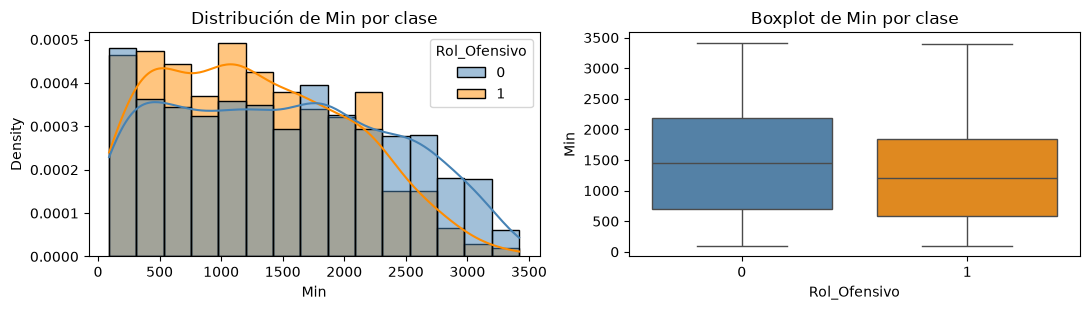

Correlación de Pearson entre Min y 90s: 1.0
Separación del cociente Min / MP (minutos por partido jugado):


,mean,median,r_pb,p_valor
Rol_Ofensivo,,,,
0,61.71,65.41,-0.267,6.62e-30
1,49.81,50.32,-0.267,6.62e-30


,Umbral,N jugadores,% Train
0,< 3 partidos (270 min),154,8.8
1,< 5 partidos (450 min),276,15.8
2,< 10 partidos (900 min),560,32.1
3,< 15 partidos (1350 min),867,49.7


In [121]:
# 1.5.3.4 Min (Minutos totales), redundancia con 90s y cociente Min / MP
analizar_variable('Min')

print('Correlación de Pearson entre Min y 90s:', round(X_train['Min'].corr(X_train['90s']), 4))

min_por_partido = X_train['Min'] / X_train['MP']
r_min_mp, _ = pointbiserialr(y_train, min_por_partido)
resumen_min_mp = train_df.assign(Min_MP=min_por_partido).groupby('Rol_Ofensivo')['Min_MP'].agg(['mean', 'std', 'median']).round(2)
resumen_min_mp['corr_target'] = round(r_min_mp, 3)
print('Separación del cociente Min / MP (minutos por partido jugado):')
display(resumen_min_mp)

tramos_min = pd.DataFrame([
    {'Umbral': f'< {p} partidos ({p*90} min)', 'N jugadores': int((X_train['Min'] < p*90).sum()),
     '% Train': round((X_train['Min'] < p*90).mean() * 100, 1)}
    for p in [3, 5, 10, 15]
])
display(tramos_min)

**Interpretación (`Min` y `90s`):** Al igual que `Starts`, `Min` tiene una correlación débil con `Rol_Ofensivo` y mucho solapamiento entre clases frente a su gran desviación típica. Su interés para el modelado está en tres puntos: (1) su escala en miles obliga a estandarizar (`StandardScaler` en `Train`) para la regularización y el MLP; (2) el cociente `Min / MP` muestra una correlación moderadamente mayor (planteando la **hipótesis** de que los atacantes juegan menos minutos por aparición debido a los cambios); y (3) en la franja de pocos minutos (`< 3` partidos completos) las tasas por 90 min serán más inestables. `90s` se elimina por ser proporcional exacta a `Min`.

#### 1.5.3.5 `Gls` (Goles totales) *(y `G+A`)*

,count,mean,std,median,r_pb,p_valor
Rol_Ofensivo,,,,,,
0,1268,1.32,2.02,1.0,0.42,2.25e-75
1,476,4.31,4.43,3.0,0.42,2.25e-75


,Variable,Umbral IQR,N Outliers (>UB),% Muestra,% Ofensivos en Outliers,% Ofensivos Base
0,Gls,7.5,120,6.9,78.3,27.3


,Player,Pos,Rol_Ofensivo,Squad,Min,Gls
1183,Harry Kane,FWMF,1,Bayern Munich,2377,36
1653,Vedat Muriqi,FW,1,Mallorca,3128,23
2308,Igor Thiago,FW,1,Brentford,3282,22
2619,Esteban Lepaul,FW,1,Rennes,2685,21
2376,Deniz Undav,FWMF,1,Stuttgart,2241,19


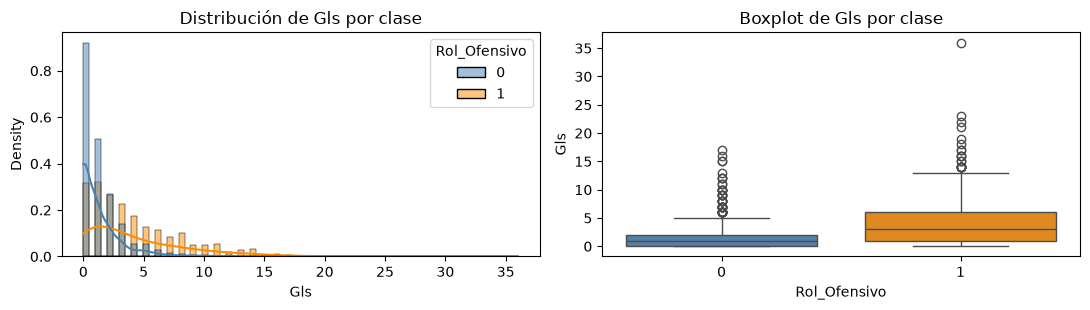

Diferencia máxima |G+A - (Gls + Ast)|: 0
Diferencia máxima |Gls - (G-PK + PK)|: 0


In [122]:
# 1.5.3.5 Gls (Goles totales) y comprobación de identidades lineales con G+A, G-PK y PK
analizar_variable('Gls')
print('Diferencia máxima |G+A - (Gls + Ast)|:', (X_train['G+A'] - (X_train['Gls'] + X_train['Ast'])).abs().max())
print('Diferencia máxima |Gls - (G-PK + PK)|:', (X_train['Gls'] - (X_train['G-PK'] + X_train['PK'])).abs().max())

**Interpretación (`Gls` y `G+A`):** Aquí sí se observa una correlación clara con `Rol_Ofensivo`, aunque sigue habiendo solapamiento en los jugadores con $0$ o $1$ gol (tanto defensas como delanteros suplentes o con mala racha). En los *outliers* de la cola derecha la mayoría son delanteros goleadores reales (**señal válida que no debe eliminarse**), aunque todavía hay una proporción apreciable de centrocampistas y defensas con gol. **Hipótesis para el modelado:** `Gls` es un predictor fuerte, pero al cumplir `Gls = G-PK + PK` generará colinealidad exacta en el modelo lineal sin regularizar de la Sección II. `G+A` se elimina por ser suma exacta `Gls + Ast`.

#### 1.5.3.6 `G-PK` (Goles sin penalti)

,count,mean,std,median,r_pb,p_valor
Rol_Ofensivo,,,,,,
0,1268,1.24,1.85,1.0,0.414,5.35e-73
1,476,3.80,3.75,3.0,0.414,5.35e-73


,Variable,Umbral IQR,N Outliers (>UB),% Muestra,% Ofensivos en Outliers,% Ofensivos Base
0,G-PK,7.5,93,5.3,78.5,27.3


,Player,Pos,Rol_Ofensivo,Squad,Min,G-PK
1183,Harry Kane,FWMF,1,Bayern Munich,2377,26
2376,Deniz Undav,FWMF,1,Stuttgart,2241,19
1653,Vedat Muriqi,FW,1,Mallorca,3128,18
2619,Esteban Lepaul,FW,1,Rennes,2685,18
1485,Lautaro Martínez,FW,1,Inter,2159,17


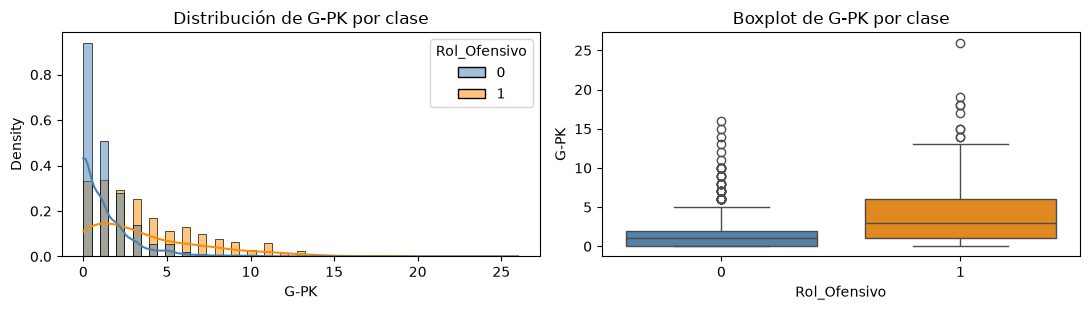

Correlación de Pearson entre Gls y G-PK: 0.9744


In [123]:
# 1.5.3.6 G-PK (Goles sin penalti)
analizar_variable('G-PK')
print('Correlación de Pearson entre Gls y G-PK:', round(X_train['Gls'].corr(X_train['G-PK']), 4))

**Interpretación (`G-PK`):** Presenta prácticamente la misma distribución, correlación y composición de *outliers* que `Gls` (**señal válida de jugadores goleadores**), sin el efecto de quién lanza los penaltis. **Hipótesis para el modelado:** dado que su correlación con `Gls` es casi uno, incluir ambas es redundante; comprobaremos en la Sección II si la regularización $L_1$ y el método *wrapper* se quedan solo con una de las dos.

#### 1.5.3.7 `PK` y `PKatt` (Penaltis convertidos e intentados)

,count,mean,std,median,r_pb,p_valor
Rol_Ofensivo,,,,,,
0,1268,0.08,0.50,0.0,0.243,8.75e-25
1,476,0.51,1.22,0.0,0.243,8.75e-25


,Variable,Umbral IQR,N Outliers (>UB),% Muestra,% Ofensivos en Outliers,% Ofensivos Base
0,PK,0.0,161,9.2,69.6,27.3


,Player,Pos,Rol_Ofensivo,Squad,Min,PK
1183,Harry Kane,FWMF,1,Bayern Munich,2377,10
2308,Igor Thiago,FW,1,Brentford,3282,8
95,Nadiem Amiri,MF,0,Mainz 05,2083,8
1806,Mikel Oyarzabal,FW,1,Real Sociedad,2710,7
607,Romain Del Castillo,MFFW,1,Brest,2625,6


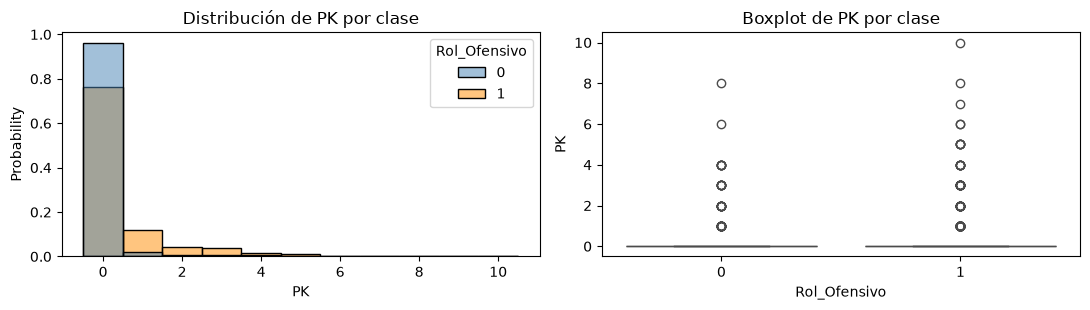

,count,mean,std,median,r_pb,p_valor
Rol_Ofensivo,,,,,,
0,1268,0.10,0.57,0.0,0.267,8.85e-30
1,476,0.66,1.43,0.0,0.267,8.85e-30


,Variable,Umbral IQR,N Outliers (>UB),% Muestra,% Ofensivos en Outliers,% Ofensivos Base
0,PKatt,0.0,199,11.4,68.3,27.3


,Player,Pos,Rol_Ofensivo,Squad,Min,PKatt
1183,Harry Kane,FWMF,1,Bayern Munich,2377,11
2308,Igor Thiago,FW,1,Brentford,3282,9
607,Romain Del Castillo,MFFW,1,Brest,2625,8
356,Ante Budimir,FW,1,Osasuna,2938,8
95,Nadiem Amiri,MF,0,Mainz 05,2083,8


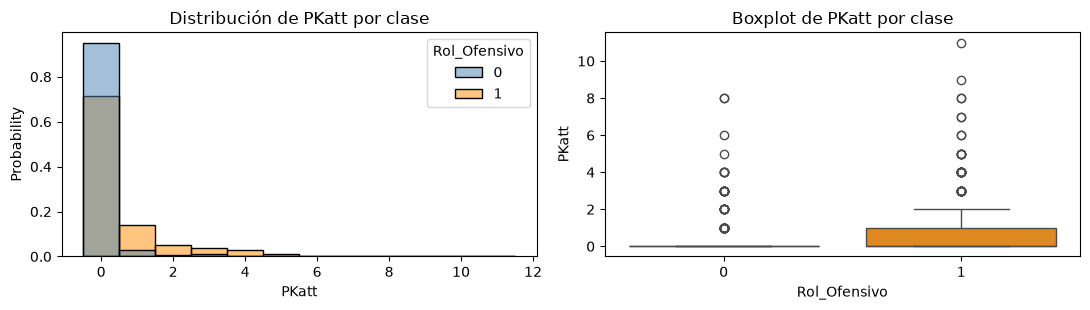

Correlación de Pearson entre PK y PKatt: 0.968


In [124]:
# 1.5.3.7 PK y PKatt (Penaltis convertidos e intentados)
analizar_variable('PK')
analizar_variable('PKatt')
print('Correlación de Pearson entre PK y PKatt:', round(X_train['PK'].corr(X_train['PKatt']), 4))

**Interpretación (`PK` y `PKatt`):** Al estar dominadas por ceros, el umbral IQR vale cero y etiqueta como *outlier* a cualquier jugador que haya tirado un penalti. Su correlación con `Rol_Ofensivo` es moderada: ser lanzador aumenta la probabilidad de ser atacante (**señal válida**), pero solo afecta a una minoría de jugadores y cerca de un tercio de los lanzadores son centrocampistas o defensas especialistas. **Hipótesis para el modelado:** `PKatt` y `PK` son casi idénticas entre sí y redundantes una vez conocidos `Gls` y `G-PK`, por lo que esperamos que a lo sumo una sobreviva a la selección de variables.

#### 1.5.3.8 `Ast` (Asistencias totales)

,count,mean,std,median,r_pb,p_valor
Rol_Ofensivo,,,,,,
0,1268,1.37,1.94,1.0,0.109,4.62e-06
1,476,1.85,1.99,1.0,0.109,4.62e-06


,Variable,Umbral IQR,N Outliers (>UB),% Muestra,% Ofensivos en Outliers,% Ofensivos Base
0,Ast,5.0,72,4.1,44.4,27.3


,Player,Pos,Rol_Ofensivo,Squad,Min,Ast
796,Bruno Fernandes,MF,0,Manchester Utd,3063,21
1767,Michael Olise,MF,0,Bayern Munich,2316,19
665,Federico Dimarco,MF,0,Inter,2698,16
2049,Julian Ryerson,MF,0,Dortmund,2266,15
483,Rayan Cherki,MF,0,Manchester City,1786,12


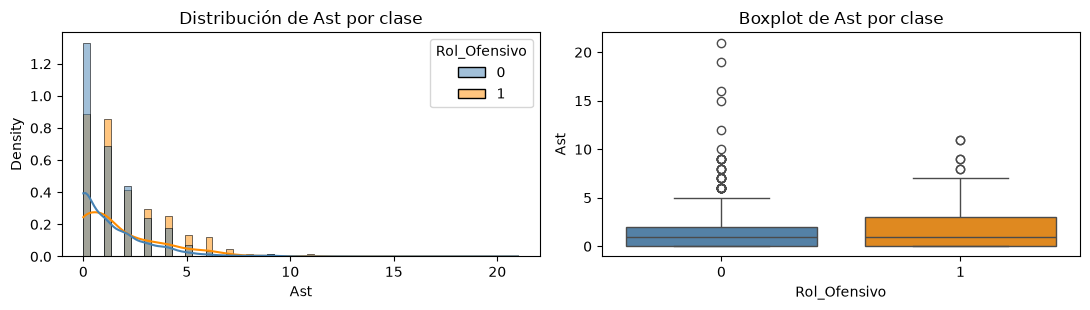

In [125]:
# 1.5.3.8 Ast (Asistencias totales)
analizar_variable('Ast')

**Interpretación (`Ast`):** Su correlación con `Rol_Ofensivo` es baja y las medianas de ambas clases son iguales. En la tabla de *outliers* y en el top 5 se observa que más de la mitad de los jugadores con más asistencias tienen etiqueta `MF` (`Rol_Ofensivo = 0`: interiores creativos, extremos catalogados como centrocampistas y carrileros). **Hipótesis para el modelado:** son datos reales válidos, pero muestran que las asistencias no son exclusivas de los delanteros, marcando una zona de solapamiento donde los modelos tendrán dificultad para separar clases solo por asistencias.

#### 1.5.3.9 `CrdY` (Tarjetas amarillas)

,count,mean,std,median,r_pb,p_valor
Rol_Ofensivo,,,,,,
0,1268,3.32,2.68,3.0,-0.186,4.30e-15
1,476,2.25,1.99,2.0,-0.186,4.30e-15


,Variable,Umbral IQR,N Outliers (>UB),% Muestra,% Ofensivos en Outliers,% Ofensivos Base
0,CrdY,8.5,68,3.9,5.9,27.3


,Player,Pos,Rol_Ofensivo,Squad,Min,CrdY
437,Carmona,DFMF,0,Sevilla,2565,13
880,James Garner,MFDF,0,Everton,3413,12
1386,Pol Lozano,MF,0,Espanyol,2157,12
1910,Marin Pongračić,DF,0,Fiorentina,2918,12
37,Lucien Agoume,MF,0,Sevilla,2686,12


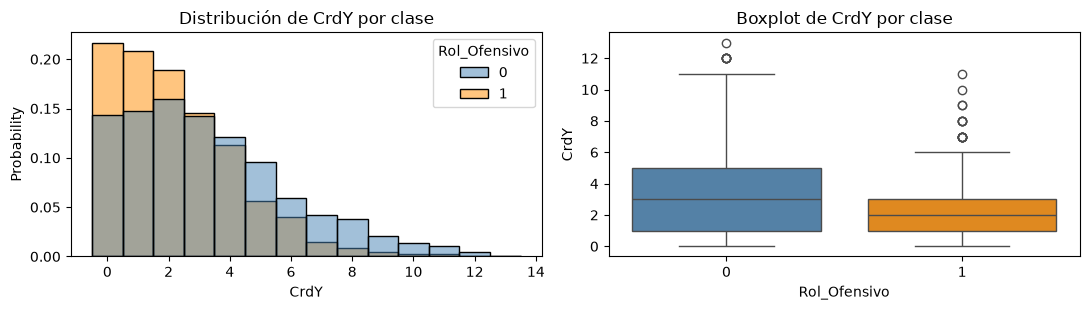

In [126]:
# 1.5.3.9 CrdY (Tarjetas amarillas)
analizar_variable('CrdY')

**Interpretación (`CrdY`):** Presenta una correlación negativa moderada con `Rol_Ofensivo` (con bastante solapamiento en los valores bajos de $1$ a $3$ tarjetas), pero en la cola superior (`N Outliers`) casi todos los jugadores son defensas o centrocampistas (**señal defensiva válida**). **Hipótesis para el modelado:** aunque por sí sola tiene poder predictivo limitado, al no medir producción ofensiva esperamos que aporte información complementaria (con coeficiente negativo) para distinguir jugadores con pocos goles.

#### 1.5.3.10 `CrdR` (Tarjetas rojas)

,count,mean,std,median,r_pb,p_valor
Rol_Ofensivo,,,,,,
0,1268,0.17,0.41,0.0,-0.072,2.62e-03
1,476,0.11,0.34,0.0,-0.072,2.62e-03


,Variable,Umbral IQR,N Outliers (>UB),% Muestra,% Ofensivos en Outliers,% Ofensivos Base
0,CrdR,0.0,252,14.4,19.4,27.3


,Player,Pos,Rol_Ofensivo,Squad,Min,CrdR
2431,Federico Viñas,FWMF,1,Oviedo,2439,3
2464,Wesley,MF,0,Roma,2448,2
2020,Cristian Romero,DF,0,Tottenham,1868,2
2635,Endrick,FWMF,1,Lyon,1227,2
1544,Nobel Mendy,DF,0,Rayo Vallecano,1797,2


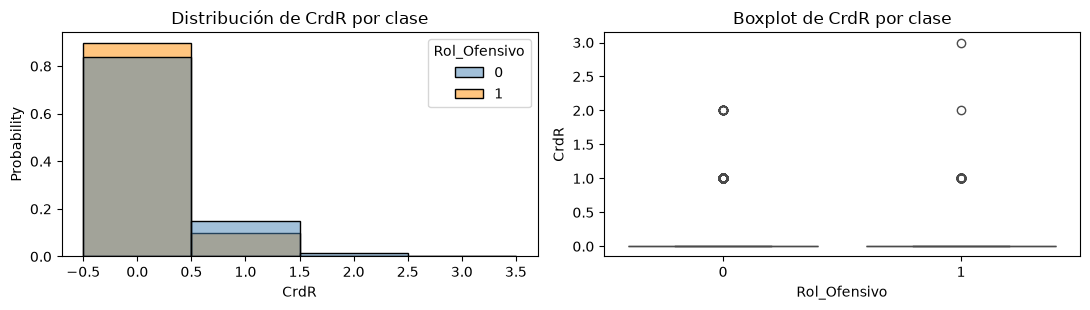

In [127]:
# 1.5.3.10 CrdR (Tarjetas rojas)
analizar_variable('CrdR')

**Interpretación (`CrdR`):** Evento muy poco frecuente donde la gran mayoría de jugadores vale cero y su correlación con `Rol_Ofensivo` es casi nula. Además, en el top 5 aparecen tanto defensas como delanteros expulsados. **Hipótesis para el modelado:** la ligera diferencia observada entre clases entra dentro de la **variabilidad estadística** de un suceso raro; esperamos que la regularización o el *wrapper* la descarten frente a `CrdY`.

#### 1.5.3.11 `Gls.1` (Goles por 90 min) *(y `G+A.1`)*

,count,mean,std,median,r_pb,p_valor
Rol_Ofensivo,,,,,,
0,1268,0.08,0.12,0.04,0.499,2.78e-110
1,476,0.28,0.22,0.24,0.499,2.78e-110


,Variable,Umbral IQR,N Outliers (>UB),% Muestra,% Ofensivos en Outliers,% Ofensivos Base,Outliers Min<270 (n),% Ofens (Min<270),% Ofens (Min>=270)
0,Gls.1,0.5,97,5.6,76.3,27.3,18,44.4,83.5


,Player,Pos,Rol_Ofensivo,Squad,Min,Gls.1
1183,Harry Kane,FWMF,1,Bayern Munich,2377,1.36
2247,Cristhian Stuani,FW,1,Girona,412,1.09
1083,Hamza Igamane,FW,1,Lille,432,1.04
2237,Orri Steinn Óskarsson,FW,1,Real Sociedad,835,0.97
1244,Adam Kölle,DF,0,Heidenheim,93,0.97


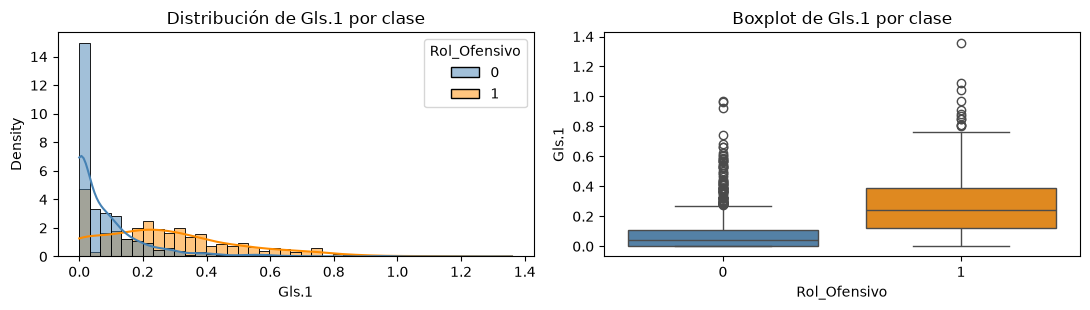

Diferencia máxima |G+A.1 - (Gls.1 + Ast.1)|: 0.01


In [128]:
# 1.5.3.11 Gls.1 (Goles por 90 min) y comprobación de G+A.1 = Gls.1 + Ast.1
analizar_variable('Gls.1', es_tasa=True)
print('Diferencia máxima |G+A.1 - (Gls.1 + Ast.1)|:', round((X_train['G+A.1'] - (X_train['Gls.1'] + X_train['Ast.1'])).abs().max(), 4))

**Interpretación (`Gls.1` y `G+A.1`):** Aunque `Gls.1` muestra la correlación más alta con `Rol_Ofensivo`, la tabla del top 5 y el desglose de *outliers* con `Min < 270` revelan que dividir entre el tiempo jugado resulta engañoso en jugadores con pocos minutos: un defensa o medio que marque un gol aislado en poco más de un partido obtiene sobre el papel una tasa goleadora de estrella mundial, cuando **si realmente tuviera ese nivel ofensivo jugaría mucho más tiempo**. Dado que ya disponemos de los goles brutos (`Gls`) y del tiempo de juego (`Min`, `Starts`, `MP`), decidimos descartar `Gls.1` (y `G+A.1`) al cierre del EDA.

#### 1.5.3.12 `G-PK.1` (Goles sin penalti por 90 min)

,count,mean,std,median,r_pb,p_valor
Rol_Ofensivo,,,,,,
0,1268,0.07,0.12,0.03,0.481,1.02e-101
1,476,0.25,0.20,0.22,0.481,1.02e-101


,Variable,Umbral IQR,N Outliers (>UB),% Muestra,% Ofensivos en Outliers,% Ofensivos Base,Outliers Min<270 (n),% Ofens (Min<270),% Ofens (Min>=270)
0,G-PK.1,0.45,103,5.9,75.7,27.3,20,40.0,84.3


,Player,Pos,Rol_Ofensivo,Squad,Min,G-PK.1
1083,Hamza Igamane,FW,1,Lille,432,1.04
1183,Harry Kane,FWMF,1,Bayern Munich,2377,0.98
2237,Orri Steinn Óskarsson,FW,1,Real Sociedad,835,0.97
1244,Adam Kölle,DF,0,Heidenheim,93,0.97
1961,Harrison Reed,MF,0,Fulham,94,0.96


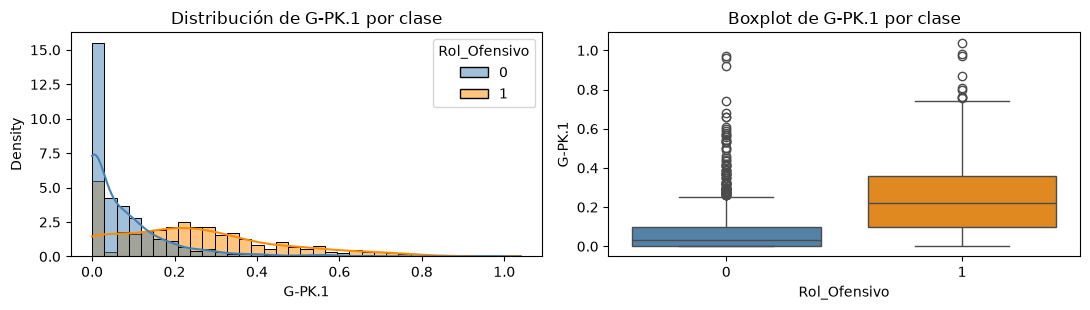

Correlación de Pearson entre Gls.1 y G-PK.1: 0.9684


In [129]:
# 1.5.3.12 G-PK.1 (Goles sin penalti por 90 min)
analizar_variable('G-PK.1', es_tasa=True)
print('Correlación de Pearson entre Gls.1 y G-PK.1:', round(X_train['Gls.1'].corr(X_train['G-PK.1']), 4))

**Interpretación (`G-PK.1`):** Ocurre exactamente el mismo problema que en `Gls.1`: en el top 5 aparecen defensas y mediocentros que disputaron apenas un partido completo y marcaron un único gol, igualando sobre el papel la tasa sin penaltis de los mejores delanteros de Europa. Para evitar introducir este sesgo de denominador pequeño en el modelado —y conservando ya `G-PK` y `Min`—, descartaremos también `G-PK.1`.

#### 1.5.3.13 `Ast.1` (Asistencias por 90 min)

,count,mean,std,median,r_pb,p_valor
Rol_Ofensivo,,,,,,
0,1268,0.08,0.12,0.05,0.15,3.20e-10
1,476,0.12,0.12,0.10,0.15,3.20e-10


,Variable,Umbral IQR,N Outliers (>UB),% Muestra,% Ofensivos en Outliers,% Ofensivos Base,Outliers Min<270 (n),% Ofens (Min<270),% Ofens (Min>=270)
0,Ast.1,0.36,65,3.7,32.3,27.3,19,10.5,41.3


,Player,Pos,Rol_Ofensivo,Squad,Min,Ast.1
1778,Frank Onyeka,MF,0,Brentford,92,0.98
865,Ben Gannon-Doak,MF,0,Bournemouth,113,0.80
1590,Rui Modesto,MF,0,Udinese,119,0.76
237,Ismael Bekhoucha,DF,0,Getafe,122,0.74
1767,Michael Olise,MF,0,Bayern Munich,2316,0.74


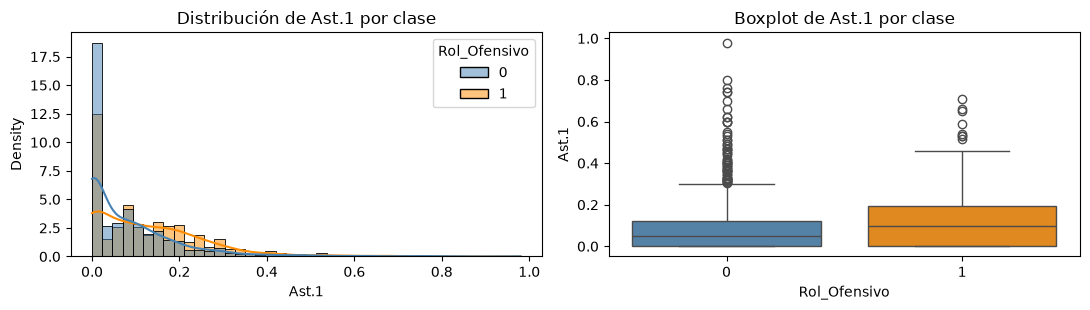

In [130]:
# 1.5.3.13 Ast.1 (Asistencias por 90 min)
analizar_variable('Ast.1', es_tasa=True)

**Interpretación (`Ast.1`):** Es el ejemplo más extremo de por qué las variables normalizadas por tiempo resultan engañosas: los jugadores con mayor `Ast.1` de todo `Train` son centrocampistas y defensas que jugaron poco más de 90 minutos y dieron una única asistencia en toda la temporada, superando en tasa a los mejores asistentes reales de Europa. Si realmente generasen ese volumen de juego ofensivo, tendrían muchos más minutos; por ello descartamos `Ast.1` y nos quedamos con el conteo real `Ast` junto a los minutos.

#### 1.5.3.14 `G+A-PK` (Goles sin penalti + Asistencias por 90 min)

,count,mean,std,median,r_pb,p_valor
Rol_Ofensivo,,,,,,
0,1268,0.16,0.18,0.11,0.439,3.88e-83
1,476,0.38,0.24,0.35,0.439,3.88e-83


,Variable,Umbral IQR,N Outliers (>UB),% Muestra,% Ofensivos en Outliers,% Ofensivos Base,Outliers Min<270 (n),% Ofens (Min<270),% Ofens (Min>=270)
0,G+A-PK,0.77,51,2.9,66.7,27.3,9,22.2,76.2


,Player,Pos,Rol_Ofensivo,Squad,Min,G+A-PK
2064,Allan Saint-Maximin,MF,0,Lens,410,1.32
1767,Michael Olise,MF,0,Bayern Munich,2316,1.32
2367,Stefanos Tzimas,FW,1,Brighton,139,1.29
615,Ousmane Dembélé,FW,1,Paris SG,1063,1.27
1083,Hamza Igamane,FW,1,Lille,432,1.25


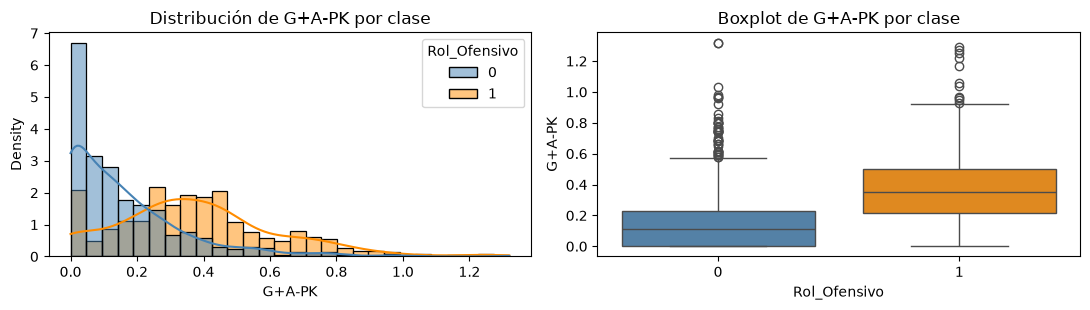

Diferencia máxima |G+A-PK - (G-PK.1 + Ast.1)|: 0.01


In [131]:
# 1.5.3.14 G+A-PK (Goles sin penalti + Asistencias por 90 min)
analizar_variable('G+A-PK', es_tasa=True)
print('Diferencia máxima |G+A-PK - (G-PK.1 + Ast.1)|:', round((X_train['G+A-PK'] - (X_train['G-PK.1'] + X_train['Ast.1'])).abs().max(), 4))

**Interpretación (`G+A-PK`):** Al ser la suma de `G-PK.1 + Ast.1`, hereda la misma distorsión en jugadores con pocos minutos (además de ser combinación lineal de ambas). Por coherencia con el descarte de todas las métricas divididas por 90 minutos, eliminaremos también `G+A-PK` al cierre del EDA.

#### 1.5.3.15 `Comp` y `traspaso` *(y `n_clubes`)*

¿Son n_clubes y traspaso 100% equivalentes en Train?: True

--- Liga (Comp) ---


Rol_Ofensivo,0,1,% Ofensivo,chi2,p_valor
Liga,,,,,
de Bundesliga,224,90,28.66,4.28,0.3698
eng Premier League,258,82,24.12,4.28,0.3698
es La Liga,265,105,28.38,4.28,0.3698
fr Ligue 1,234,101,30.15,4.28,0.3698
it Serie A,287,98,25.45,4.28,0.3698



--- Traspaso invernal ---


Rol_Ofensivo,0,1,% Ofensivo,chi2,p_valor
traspaso,,,,,
False,1197,431,26.47,7.67,0.0056
True,71,45,38.79,7.67,0.0056


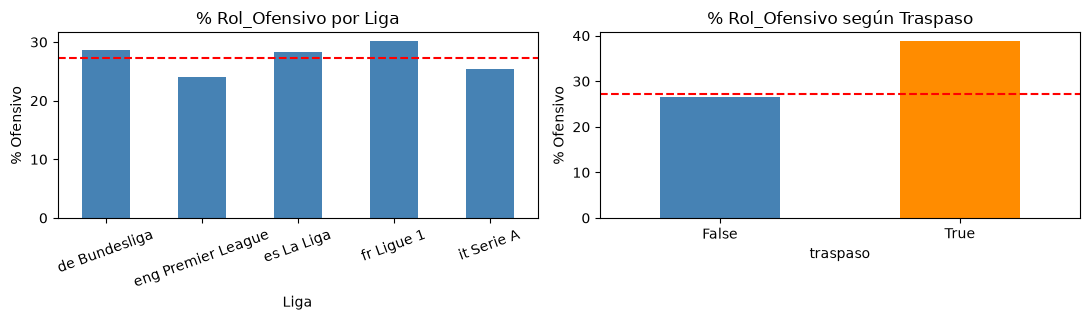

In [132]:
# 1.5.3.15 Comp (Liga) y traspaso (y comprobación de equivalencia con n_clubes)
print('¿Son n_clubes y traspaso 100% equivalentes en Train?:', (X_train['n_clubes'] == (X_train['traspaso'].astype(int) + 1)).all())

comp_cols = ['Comp_eng Premier League', 'Comp_es La Liga', 'Comp_fr Ligue 1', 'Comp_it Serie A']
liga_train = pd.Series('de Bundesliga', index=X_train.index, name='Liga')
for cc in comp_cols:
    liga_train.loc[X_train[cc].astype(int) == 1] = cc.replace('Comp_', '')

for nombre, serie in [('Liga (Comp)', liga_train), ('Traspaso invernal', X_train['traspaso'])]:
    ct = pd.crosstab(serie, y_train)
    chi2, p_val, _, _ = chi2_contingency(ct)
    ct['N'] = ct.sum(axis=1)
    ct['% Ofensivo'] = (ct[1] / ct['N'] * 100).round(2)
    ct['chi2'] = round(chi2, 2)
    ct['p_valor'] = round(p_val, 4)
    print(f'\n--- {nombre} ---')
    display(ct)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
(pd.crosstab(liga_train, y_train, normalize='index')[1] * 100).plot(kind='bar', color='steelblue', ax=ax[0])
ax[0].axhline(y_train.mean() * 100, color='red', linestyle='--')
ax[0].set_title('% Rol_Ofensivo por Liga')
ax[0].set_ylabel('% Ofensivo')
ax[0].tick_params(axis='x', rotation=20)

(pd.crosstab(X_train['traspaso'], y_train, normalize='index')[1] * 100).plot(kind='bar', color=['steelblue', 'darkorange'], ax=ax[1])
ax[1].axhline(y_train.mean() * 100, color='red', linestyle='--')
ax[1].set_title('% Rol_Ofensivo según Traspaso')
ax[1].set_ylabel('% Ofensivo')
ax[1].tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

**Interpretación (`Comp`, `traspaso` y `n_clubes`):**
* En **`Comp` (Liga)** las pequeñas diferencias entre competiciones no son significativas y entran dentro de la variabilidad normal entre muestras.
* En **`traspaso`**, aunque el porcentaje de atacantes es algo mayor entre los jugadores traspasados, el tamaño de ese subgrupo (`N`) es pequeño (apenas una docena de jugadores de diferencia entre clases), por lo que puede deberse perfectamente a **variabilidad estadística** de una única ventana de invierno.
* **Hipótesis para el modelado:** tanto `Comp` como `traspaso` tienen un peso individual muy bajo y esperamos que sean descartadas por la regularización $L_1$ o los métodos *wrapper*. Además, `n_clubes` es $100\%$ equivalente a `traspaso` y se elimina.

### 1.5.4 Clustering de Correlaciones (Dendrograma) e Información Mutua

En lugar de inspeccionar únicamente matrices de números, aplicamos **clustering jerárquico aglomerativo** sobre la distancia de correlación $d_{ij} = 1 - |r_{ij}|$ en `X_train` (tanto con **Pearson** como con **Spearman**) para agrupar automáticamente las variables colineales mediante un **dendrograma**. A continuación comparamos la correlación lineal frente a la **Información Mutua** con `Rol_Ofensivo`.

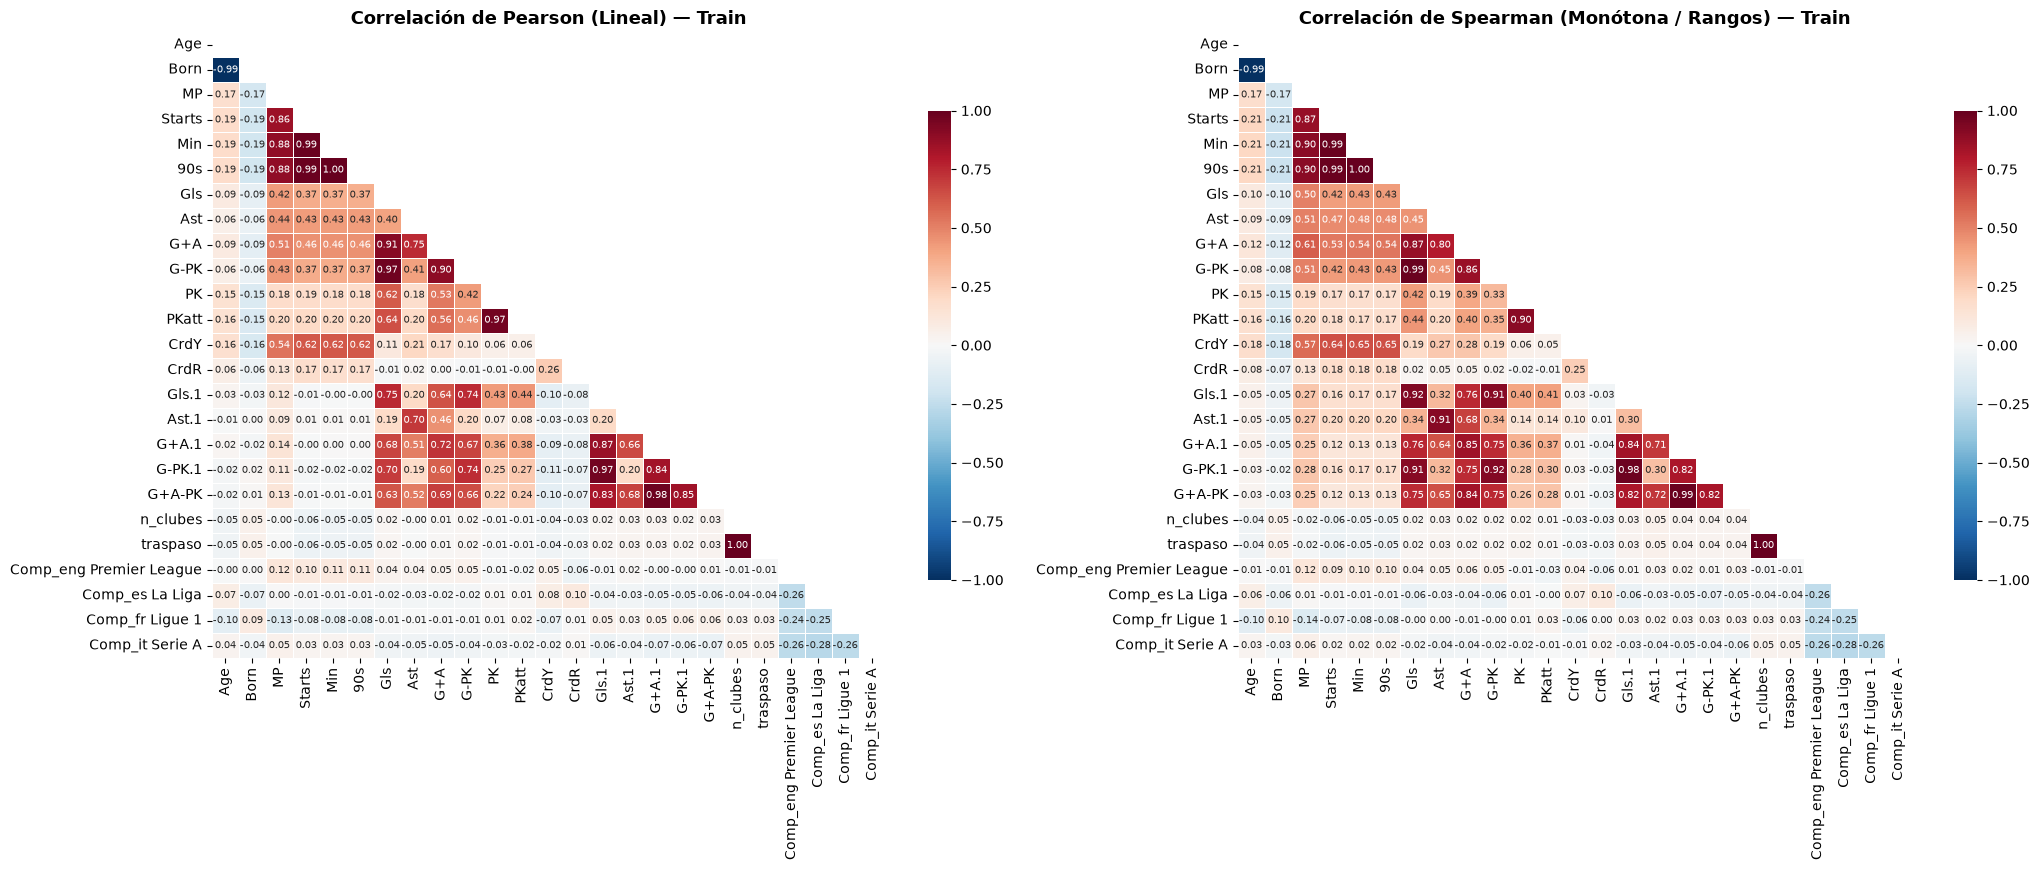

,Variable 1,Variable 2,Pearson (r),Spearman (ρ),Diagnóstico
0,Min,90s,1.0000,1.0000,Redundancia estructural directa
1,n_clubes,traspaso,1.0000,1.0000,Redundancia estructural directa
2,Age,Born,-0.9940,-0.9936,Redundancia estructural directa
3,Starts,90s,0.9906,0.9902,Colinealidad empírica fuerte
4,Starts,Min,0.9906,0.9902,Colinealidad empírica fuerte
5,G+A.1,G+A-PK,0.9815,0.9892,Colinealidad empírica fuerte
6,Gls,G-PK,0.9744,0.9886,Colinealidad empírica fuerte
7,Gls.1,G-PK.1,0.9684,0.9799,Colinealidad empírica fuerte
8,PK,PKatt,0.9680,0.9012,Colinealidad empírica fuerte
9,Gls,G+A,0.9108,0.8698,Colinealidad empírica fuerte


Comprobación de identidades lineales de 3 variables en X_train:
  max |G+A - (Gls + Ast)|           = 0.0000
  max |Gls - (G-PK + PK)|           = 0.0000
  max |G+A.1 - (Gls.1 + Ast.1)|     = 0.0100
  max |G+A-PK - (G-PK.1 + Ast.1)|   = 0.0100 (diferencia solo por redondeo FBref)


In [133]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import squareform

# Matriz numérica completa de X_train
X_train_num = X_train.copy()
for c in X_train_num.columns:
    if not pd.api.types.is_numeric_dtype(X_train_num[c]):
        X_train_num[c] = X_train_num[c].astype(int)

corr_pearson = X_train_num.corr(method='pearson')
corr_spearman = X_train_num.corr(method='spearman')

# Distancias de correlación d(i, j) = 1 - |r_ij|
dist_p = 1 - np.abs(corr_pearson.values)
dist_s = 1 - np.abs(corr_spearman.values)
np.fill_diagonal(dist_p, 0)
np.fill_diagonal(dist_s, 0)

Z_pearson = linkage(squareform(np.clip(dist_p, 0, None)), method='average')
Z_spearman = linkage(squareform(np.clip(dist_s, 0, None)), method='average')
umbral_dist = 0.25  # equivale a correlación media |r| >= 0.75 dentro del clúster

# Dendrogramas comparativos (Pearson vs. Spearman)
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))

dendrogram(Z_pearson, labels=X_train_num.columns, leaf_rotation=55, leaf_font_size=9,
           color_threshold=umbral_dist, ax=axes[0])
axes[0].axhline(umbral_dist, color='crimson', linestyle='--', linewidth=1.3,
                label=f'Corte d = {umbral_dist} (|r| >= {1-umbral_dist:.2f})')
axes[0].set_ylabel('Distancia: 1 - |r de Pearson|')
axes[0].set_title('Dendrograma de Correlación de Pearson (Lineal) — Train', fontweight='bold')
axes[0].legend()
axes[0].grid(axis='y', linestyle='--', alpha=0.35)

dendrogram(Z_spearman, labels=X_train_num.columns, leaf_rotation=55, leaf_font_size=9,
           color_threshold=umbral_dist, ax=axes[1])
axes[1].axhline(umbral_dist, color='crimson', linestyle='--', linewidth=1.3,
                label=f'Corte d = {umbral_dist} (|ρ| >= {1-umbral_dist:.2f})')
axes[1].set_ylabel('Distancia: 1 - |ρ de Spearman|')
axes[1].set_title('Dendrograma de Correlación de Spearman (Rangos) — Train', fontweight='bold')
axes[1].legend()
axes[1].grid(axis='y', linestyle='--', alpha=0.35)

plt.tight_layout()
plt.show()

# Tabla de clústeres formados en Pearson y en Spearman al cortar en d = 0.25 (|r| >= 0.75)
cl_p = fcluster(Z_pearson, t=umbral_dist, criterion='distance')
cl_s = fcluster(Z_spearman, t=umbral_dist, criterion='distance')

for nombre, cl in [('Clústeres por Pearson (Lineal, |r| >= 0.75)', cl_p),
                   ('Clústeres por Spearman (Monótona, |ρ| >= 0.75)', cl_s)]:
    df_cl = pd.DataFrame({'Variable': X_train_num.columns, 'Cluster': cl})
    resumen_cl = (
        df_cl.groupby('Cluster')['Variable']
        .agg(N_Variables='count', Variables_Agrupadas=lambda s: ', '.join(s))
        .sort_values('N_Variables', ascending=False)
        .reset_index(drop=True)
    )
    print(f'\n--- {nombre} ---')
    display(resumen_cl[resumen_cl['N_Variables'] > 1])

# Comprobación algebraica de identidades lineales exactas de 3 variables
print('\nComprobación de identidades lineales de 3 variables en X_train:')
print(f"  max |G+A - (Gls + Ast)|         = {(X_train_num['G+A'] - (X_train_num['Gls'] + X_train_num['Ast'])).abs().max():.4f}")
print(f"  max |Gls - (G-PK + PK)|         = {(X_train_num['Gls'] - (X_train_num['G-PK'] + X_train_num['PK'])).abs().max():.4f}")
print(f"  max |G+A.1 - (Gls.1 + Ast.1)|   = {(X_train_num['G+A.1'] - (X_train_num['Gls.1'] + X_train_num['Ast.1'])).abs().max():.4f}")
print(f"  max |G+A-PK - (G-PK.1 + Ast.1)| = {(X_train_num['G+A-PK'] - (X_train_num['G-PK.1'] + X_train_num['Ast.1'])).abs().max():.4f}")

El dendrograma de **Pearson** agrupa a distancia prácticamente cero las redundancias estructurales (`Min`–`90s`, `n_clubes`–`traspaso`, `Age`–`Born`) y separa cuatro bloques colineales: **tasas por 90 min** (`Gls.1, G+A.1, G-PK.1, G+A-PK`), **tiempo de participación** (`MP, Starts, Min, 90s`), **goles absolutos** (`Gls, G+A, G-PK`) y **penaltis** (`PK, PKatt`). En el dendrograma de **Spearman**, además, el clúster de tasas por 90 minutos se fusiona directamente con el de goles absolutos (y `Ast.1` se une con `Ast`), confirmando que las variables por 90 minutos contienen esencialmente la misma información ordenada que los conteos brutos pero distorsionada por el cociente en jugadores con pocos minutos. Por ello, en `1.5.5` descartaremos el clúster de tasas por 90 min junto a las redundancias estructurales y conservaremos los bloques de conteos y participación para la Sección II.

,Información Mutua (MI),MI (std),Corr. Biserial Puntual (r),Corr. Spearman (ρ)
Variable,,,,
Gls.1,0.1454,0.0067,0.4986,0.4713
G-PK.1,0.1350,0.0089,0.4811,0.4592
G+A.1,0.1312,0.0065,0.4592,0.4501
G+A-PK,0.1230,0.0098,0.4392,0.4367
Gls,0.0898,0.0068,0.4197,0.4046
G-PK,0.0865,0.0116,0.4135,0.3937
G+A,0.0667,0.0111,0.3553,0.3426
PKatt,0.0436,0.0065,0.2667,0.3313
PK,0.0399,0.0082,0.2426,0.3022


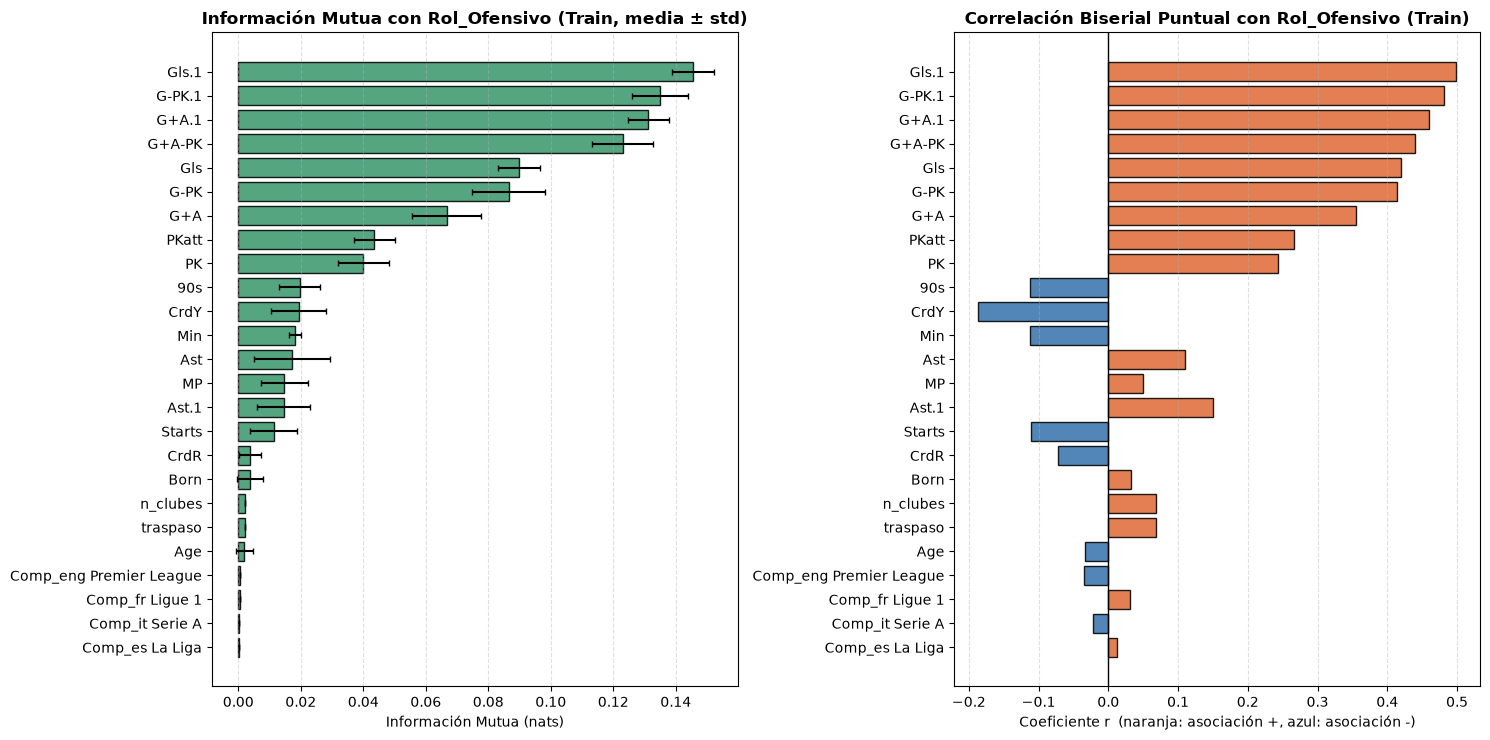

In [134]:
# Máscara booleana de variables discretas/binarias para mutual_info_classif
discrete_mask = [c in cat_cols or c == 'n_clubes' for c in X_train_num.columns]

# Promedio sobre 10 semillas para estabilizar el estimador k-NN de Información Mutua
mi_seeds = np.array([
    mutual_info_classif(X_train_num, y_train, discrete_features=discrete_mask, random_state=42 + s)
    for s in range(10)
])
mi_mean = mi_seeds.mean(axis=0)
mi_std = mi_seeds.std(axis=0)

filas_asoc = []
for idx, c in enumerate(X_train_num.columns):
    r_pb, _ = pointbiserialr(y_train, X_train_num[c])
    r_sp, _ = spearmanr(y_train, X_train_num[c])
    filas_asoc.append({
        'Variable': c,
        'Información Mutua (MI)': round(mi_mean[idx], 4),
        'MI (std)': round(mi_std[idx], 4),
        'Corr. Biserial (r)': round(r_pb, 4),
        'Corr. Spearman (ρ)': round(r_sp, 4)
    })
asoc_df = pd.DataFrame(filas_asoc).sort_values('Información Mutua (MI)', ascending=False).set_index('Variable')
display(asoc_df)

# Gráfico comparativo: Información Mutua vs. Correlación Biserial Puntual (con signo)
fig, axes = plt.subplots(1, 2, figsize=(15, 7.5))

asoc_plot = asoc_df.iloc[::-1]
axes[0].barh(
    asoc_plot.index, asoc_plot['Información Mutua (MI)'],
    xerr=asoc_plot['MI (std)'], color='#3D9970', edgecolor='black', alpha=0.88, capsize=2.5
)
axes[0].set_title('Información Mutua con Rol_Ofensivo (Train, media ± std)', fontweight='bold')
axes[0].set_xlabel('Información Mutua (nats)')
axes[0].grid(axis='x', linestyle='--', alpha=0.4)

colores_corr = ['#E06D3B' if v >= 0 else '#3B75AF' for v in asoc_plot['Corr. Biserial (r)']]
axes[1].barh(
    asoc_plot.index, asoc_plot['Corr. Biserial (r)'],
    color=colores_corr, edgecolor='black', alpha=0.88
)
axes[1].axvline(0, color='black', linewidth=1.0)
axes[1].set_title('Correlación Biserial Puntual con Rol_Ofensivo (Train)', fontweight='bold')
axes[1].set_xlabel('Coeficiente r  (naranja: asociación +, azul: asociación -)')
axes[1].grid(axis='x', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

Al descartar las variables por 90 minutos por resultar engañosas en jugadores con poco tiempo de juego, la señal principal del conjunto de datos pasa a estar encabezada por los **goles absolutos (`Gls` y `G-PK`)**, seguidos en un segundo escalón por los **penaltis (`PKatt`, `PK`)**, las **tarjetas amarillas (`CrdY`, con correlación negativa)**, el **tiempo de juego (`Min`, `Starts`)** y las **asistencias (`Ast`)**. Por último, `CrdR`, `traspaso`, `MP` aislada, `Age` y las *dummies* de liga (`Comp_*`) muestran Información Mutua y correlación prácticamente nulas, siendo compatibles con variabilidad estadística.

Además, al eliminar los cocientes precalculados por 90 minutos, surge una **hipótesis muy clara para comparar la Sección II (Lineal) con la Sección III (MLP)**: mientras que el modelo lineal solo puede combinar los goles brutos (`Gls`) y los minutos (`Min`) de forma aditiva, el MLP podrá aprender directamente la relación no lineal entre producción bruta y tiempo en el campo sin sufrir la distorsión de dividir por denominadores pequeños.

## 1.6 Feature Engineering y Construcción del Dataset de Modelado

A partir de las conclusiones del EDA construimos el conjunto de datos definitivo para `X_train` y `X_test` en dos pasos:

1. **Descarte de variables redundantes, engañosas o sin señal:**
   * *Redundancias estructurales:* `Born` ($\leftrightarrow$ `Age`), `90s` ($\leftrightarrow$ `Min`), `G+A` ($= \text{Gls} + \text{Ast}$), `n_clubes` ($\leftrightarrow$ `traspaso`) y `PK` (muy colineal con `PKatt` y causante de la dependencia exacta `Gls = G-PK + PK`).
   * *Variables normalizadas por 90 minutos (`Gls.1`, `Ast.1`, `G+A.1`, `G-PK.1`, `G+A-PK`):* descartadas porque un jugador con pocos minutos y una acción puntual obtiene una tasa inflada engañosa (si realmente rindiera a ese nivel ofensivo, jugaría mucho más tiempo).
   * *Variables sin señal individual (compatibles con variabilidad estadística):* `Age`, `CrdR`, `traspaso` y las 4 *dummies* de `Comp`.

2. **Creación de 7 métricas típicas en analítica de fútbol** (calculadas fila a fila a partir de los conteos y partidos jugados, sin dividir por minutos ni filtrar información entre `Train` y `Test`):
   * **`Gls_por_MP` (`Gls / MP`):** goles por partido disputado (mide regularidad goleadora por aparición sin inflar a quien juega solo 10 minutos al final).
   * **`Especializacion_Gol` (`G-PK / (G-PK + Ast + 1)`):** peso del gol de jugada sobre su producción ofensiva total (separa a delanteros finalizadores de centrocampistas asistentes).
   * **`Ratio_Gol_Tarjeta` (`(Gls + 1) / (CrdY + 1)`):** balance entre producción goleadora e intensidad defensiva/disciplinaria.
   * **`Lanzador_PK` (`(PKatt > 0).astype(int)`):** indicador binario de si es lanzador de penaltis del equipo.
   * **`Tasa_Titular` (`Starts / MP`):** proporción de sus apariciones en las que sale en el once titular frente a entrar como revulsivo.
   * **`Min_por_MP` (`Min / MP`):** minutos medios disputados cada vez que participa (captura el efecto sustitución de los atacantes).
   * **`CrdY_por_MP` (`CrdY / MP`):** tarjetas amarillas por partido jugado.

In [135]:
def crear_dataset_modelado(df_in):
    d = df_in.copy()
    fe = pd.DataFrame(index=d.index)

    # 1. Variables originales útiles (conteos brutos y participación)
    fe['MP'] = d['MP']
    fe['Starts'] = d['Starts']
    fe['Min'] = d['Min']
    fe['Gls'] = d['Gls']
    fe['G-PK'] = d['G-PK']
    fe['Ast'] = d['Ast']
    fe['PKatt'] = d['PKatt']
    fe['CrdY'] = d['CrdY']

    # 2. Métricas típicas de fútbol (Feature Engineering sin tasas por 90 min engañosas)
    fe['Gls_por_MP'] = d['Gls'] / d['MP']
    fe['Especializacion_Gol'] = d['G-PK'] / (d['G-PK'] + d['Ast'] + 1.0)
    fe['Ratio_Gol_Tarjeta'] = (d['Gls'] + 1.0) / (d['CrdY'] + 1.0)
    fe['Lanzador_PK'] = (d['PKatt'] > 0).astype(int)
    fe['Tasa_Titular'] = d['Starts'] / d['MP']
    fe['Min_por_MP'] = d['Min'] / d['MP']
    fe['CrdY_por_MP'] = d['CrdY'] / d['MP']

    return fe


vars_originales = ['MP', 'Starts', 'Min', 'Gls', 'G-PK', 'Ast', 'PKatt', 'CrdY']
X_train = crear_dataset_modelado(X_train)
X_test = crear_dataset_modelado(X_test)

assert list(X_train.columns) == list(X_test.columns), 'Desalineación entre Train y Test'
assert X_train.isna().sum().sum() == 0 and X_test.isna().sum().sum() == 0, 'Presencia de nulos'

rango_final = np.linalg.matrix_rank(X_train.values)
print(f'X_train final para modelado : {X_train.shape} | Rango matricial = {rango_final}/{X_train.shape[1]} (rango completo)')
print(f'X_test reservado (congelado): {X_test.shape} | Nulos = {X_test.isna().sum().sum()}')

# Evaluación de Información Mutua y Correlación de las 15 variables finales sobre Train
mask_disc_fe = [c == 'Lanzador_PK' for c in X_train.columns]
mi_fe = np.mean([
    mutual_info_classif(X_train, y_train, discrete_features=mask_disc_fe, random_state=42 + s)
    for s in range(10)
], axis=0)

filas_fe = []
for idx, c in enumerate(X_train.columns):
    r_pb, _ = pointbiserialr(y_train, X_train[c])
    r_sp, _ = spearmanr(y_train, X_train[c])
    filas_fe.append({
        'Variable': c,
        'Origen': 'Original (Conteo / Volumen)' if c in vars_originales else 'Nueva (Feature Engineering)',
        'Mín': round(X_train[c].min(), 2),
        'Máx': round(X_train[c].max(), 2),
        'Media': round(X_train[c].mean(), 2),
        'Std': round(X_train[c].std(), 2),
        'MI (Target)': round(mi_fe[idx], 4),
        'Corr r_pb': round(r_pb, 4),
        'Spearman ρ': round(r_sp, 4)
    })

tabla_admisibles = pd.DataFrame(filas_fe).sort_values('MI (Target)', ascending=False).set_index('Variable')
display(tabla_admisibles)

# Visualización del aporte de las nuevas métricas frente a las originales
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
plot_df = tabla_admisibles.iloc[::-1]
colores_origen = ['#E06D3B' if o.startswith('Nueva') else '#3B75AF' for o in plot_df['Origen']]

axes[0].barh(plot_df.index, plot_df['MI (Target)'], color=colores_origen, edgecolor='black', alpha=0.9)
axes[0].set_title('Información Mutua — Dataset Final (Naranja: Nuevas | Azul: Originales)', fontweight='bold', fontsize=10.5)
axes[0].set_xlabel('Información Mutua (nats)')
axes[0].grid(axis='x', linestyle='--', alpha=0.4)

axes[1].barh(plot_df.index, plot_df['Corr r_pb'], color=colores_origen, edgecolor='black', alpha=0.9)
axes[1].axvline(0, color='black', linewidth=1)
axes[1].set_title('Correlación Lineal (r_pb) — Dataset Final', fontweight='bold', fontsize=10.5)
axes[1].set_xlabel('Coeficiente r_pb')
axes[1].grid(axis='x', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

X_train listo para modelado : (1744, 20) | Rango=19/20 | Nulos=0
X_test reservado (congelado): (437, 20) | Nulos=0


,Bloque,Dtype,Mín,Máx,Media,Std,MI (Target),Corr r_pb (Target)
Age,Demografía,float64,15.0,41.00,25.117,4.361,0.002,-0.033
MP,Participación,int64,1.0,39.00,22.860,9.437,0.015,0.050
Starts,Participación,int64,0.0,38.00,15.948,10.198,0.011,-0.110
Min,Participación,int64,90.0,3420.00,1427.576,857.708,0.018,-0.113
Gls,Producción absoluta,int64,0.0,36.00,2.133,3.177,0.090,0.420
Ast,Producción absoluta,int64,0.0,21.00,1.502,1.967,0.017,0.109
G-PK,Producción absoluta,int64,0.0,26.00,1.935,2.762,0.086,0.414
PK,Penaltis,int64,0.0,10.00,0.198,0.788,0.040,0.243
PKatt,Penaltis,int64,0.0,11.00,0.255,0.926,0.044,0.267
CrdY,Disciplina,int64,0.0,13.00,3.026,2.551,0.019,-0.186


#### Interpretación del Dataset Final y Notas para la Zona de Modelizado

La tabla y las gráficas muestran el resultado del *Feature Engineering*:
* **Las nuevas métricas futbolísticas lideran el poder predictivo sin el sesgo de pocos minutos:** `Ratio_Gol_Tarjeta`, `Gls_por_MP` y `Especializacion_Gol` se sitúan en la parte alta tanto en Información Mutua como en correlación, superando o complementando a los conteos brutos (`Gls`, `G-PK`).
* **Mejora en el bloque de participación y disciplina:** las métricas relativas por partido jugado (`Min_por_MP`, `CrdY_por_MP`, `Tasa_Titular`) y el indicador `Lanzador_PK` multiplican la señal de sus variables brutas de origen (`Min`, `Starts`, `CrdY`, `PKatt`).
* **Matriz de diseño limpia y de rango completo:** tras eliminar las variables sin señal (`Age`, `Comp_*`, `traspaso`, `CrdR`), las redundancias estructurales (`Born`, `90s`, `G+A`, `n_clubes`, `PK`) y las tasas por 90 minutos engañosas, `X_train` y `X_test` quedan con **15 variables predictoras útiles** y **rango matricial completo ($15/15$)**.

##### Notas e Hipótesis para la Zona de Modelizado (Secciones II y III)
1. **Métricas de evaluación ante el desbalanceo:** Emplearemos **Balanced Accuracy**, **F1-Score**, **ROC-AUC** y **Accuracy**.
2. **Escalado obligatorio (`StandardScaler` ajustado solo en `X_train`):** Las 15 variables combinan proporciones en $[0, 1]$ (`Tasa_Titular`, `Especializacion_Gol`) con minutos en miles (`Min`), por lo que en la Sección II habrá que tener en cuenta la escala al interpretar coeficientes y será indispensable estandarizar antes de aplicar regularización ($L_1$/$L_2$) y antes de entrenar el MLP (Sección III).
3. **Colinealidad entre variables originales y derivadas (Sección II):** Como hemos conservado tanto las variables base (`Gls`, `G-PK`, `Min`, `Starts`, `CrdY`, `PKatt`) como las métricas construidas a partir de ellas (`Gls_por_MP`, `Ratio_Gol_Tarjeta`, `Min_por_MP`, `Tasa_Titular`, `Lanzador_PK`), existe correlación fuerte dentro de cada familia. Nuestra **hipótesis para la Sección II** es que el modelo lineal sin regularizar (`penalty=None`) repartirá o cancelará pesos entre las variables originales y sus versiones derivadas, mientras que la regularización $L_1$ y el método *wrapper* seleccionarán el subconjunto más informativo (comprobando qué métricas de *feature engineering* desplazan a los conteos brutos).
4. **Esquema lineal con *Feature Engineering* vs. MLP (Sección III):** Al haber incorporado en `X_train` cocientes no lineales con sentido futbolístico (`Gls / MP`, `Min / MP`, `Starts / MP`, `(Gls+1)/(CrdY+1)`), hemos inyectado parte de la no-linealidad directamente en el espacio de características. Nuestra **hipótesis para la Sección III** es comprobar en validación si esta ingeniería de características permite al esquema lineal acercarse al rendimiento del MLP, o si las capas ocultas del MLP aún logran una mejora adicional al combinar estas 15 variables.

---

# 2. Modelado: Baselines y Esquema Lineal (Sección II)

Seguimos una estrategia de complejidad creciente sobre el mismo conjunto de entrenamiento (`X_train`, 5-Fold CV estratificada) y evaluando todos los modelos sobre la misma partición reservada (`X_test`):
1. **Modelos Baseline:** un clasificador trivial de clase mayoritaria (`DummyClassifier`) y una **heurística futbolística de una sola regla** sobre `Gls_por_MP`.
2. **Esquemas Lineales (Sección II):** Regresión Logística sin regularización, con regularización ($L_1$/$L_2$) y con selección de características *wrapper* (SFS).
3. **Métodos basados en Árboles (Sección 3):** Árbol de Decisión, Random Forest y Gradient Boosting.
4. **Red Neuronal — Perceptrón Multicapa o MLP (Sección III):** MLP de una capa oculta, MLP multicapa (aprendizaje por lote completo con parada temprana en validación) y selección *wrapper* con MLP transferida al esquema lineal.
5. **Comparativa global y obtención de estadísticos en Test (Sección IV).**

### 2.1 Configuración de Evaluación y Modelos Baseline (Dummy + Heurística Futbolística)

Para evaluar todos los modelos de forma homogénea utilizamos **cuatro figuras de mérito** adecuadas a nuestro problema de clasificación binaria desbalanceada:
* **Balanced Accuracy:** media entre la tasa de acierto en atacantes (Sensibilidad / *Recall*) y en no atacantes (Especificidad). Da el mismo peso a ambas clases y será nuestra métrica principal de validación.
* **F1-Score:** media armónica entre Precisión y Exhaustividad (*Recall*) sobre la clase positiva (`Rol_Ofensivo = 1`).
* **ROC-AUC:** área bajo la curva ROC, que mide la capacidad de ordenar las probabilidades predichas independientemente del umbral de corte.
* **Accuracy:** proporción global de aciertos (incluida para contrastar cómo se comporta frente a la clase mayoritaria).

Establecemos dos puntos de partida (*baselines*):
1. **`B0: Dummy (Clase Mayoritaria)`:** predice siempre `0` (`No Ofensivo`).
2. **`B1: Heurística Futbolística`:** regla sencilla de dominio que clasifica como atacante a todo jugador cuyos goles por partido (`Gls_por_MP`) superen un umbral calibrado únicamente sobre `X_train`.

In [ ]:
import copy, warnings
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_score, GridSearchCV, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import balanced_accuracy_score, f1_score, roc_auc_score, accuracy_score, confusion_matrix, roc_curve

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
SCORING = {'bal_acc': 'balanced_accuracy', 'f1': 'f1', 'roc_auc': 'roc_auc', 'acc': 'accuracy'}
resultados_modelos = []
predicciones_test = {}


def evaluar_y_registrar(nombre, familia, modelo, cols=None, val_bal_override=None):
    cols_u = list(X_train.columns) if cols is None else list(cols)
    X_tr_c, X_te_c = X_train[cols_u], X_test[cols_u]

    if val_bal_override is None:
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            cv_res = cross_validate(modelo, X_tr_c, y_train, cv=cv5, scoring=SCORING, n_jobs=-1)
        val_bal = cv_res['test_bal_acc'].mean()
    else:
        val_bal = val_bal_override

    m_fit = copy.deepcopy(modelo)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        m_fit.fit(X_tr_c, y_train)
    y_pred = m_fit.predict(X_te_c)
    y_prob = m_fit.predict_proba(X_te_c)[:, 1]

    fila = {
        'Modelo': nombre,
        'Familia': familia,
        'N_Vars': len(cols_u),
        'Bal_Acc (Val)': round(val_bal, 4),
        'Balanced Accuracy': round(balanced_accuracy_score(y_test, y_pred), 4),
        'F1-Score': round(f1_score(y_test, y_pred), 4),
        'ROC-AUC': round(roc_auc_score(y_test, y_prob), 4),
        'Accuracy': round(accuracy_score(y_test, y_pred), 4),
        'Variables': 'Todas (15)' if len(cols_u) == X_train.shape[1] else ', '.join(cols_u)
    }
    resultados_modelos.append(fila)
    predicciones_test[nombre] = (y_pred, y_prob, m_fit, cols_u)
    return m_fit


# 1. Baseline B0: Clasificador de clase mayoritaria
evaluar_y_registrar('B0: Dummy (Clase Mayoritaria)', '1. Baseline', DummyClassifier(strategy='most_frequent'))

# 2. Baseline B1: Heurística futbolística (umbral sobre Gls_por_MP calibrado solo en Train)
umbrales = np.linspace(0.02, 0.30, 50)
mejor_u = max(umbrales, key=lambda u: balanced_accuracy_score(y_train, (X_train['Gls_por_MP'] >= u).astype(int)))
yp_tr_h = (X_train['Gls_por_MP'] >= mejor_u).astype(int)
yp_te_h = (X_test['Gls_por_MP'] >= mejor_u).astype(int)

nombre_h = f'B1: Heurística (Gls_por_MP >= {mejor_u:.2f})'
resultados_modelos.append({
    'Modelo': nombre_h,
    'Familia': '1. Baseline',
    'N_Vars': 1,
    'Bal_Acc (Val)': round(balanced_accuracy_score(y_train, yp_tr_h), 4),
    'Balanced Accuracy': round(balanced_accuracy_score(y_test, yp_te_h), 4),
    'F1-Score': round(f1_score(y_test, yp_te_h), 4),
    'ROC-AUC': round(roc_auc_score(y_test, X_test['Gls_por_MP']), 4),
    'Accuracy': round(accuracy_score(y_test, yp_te_h), 4),
    'Variables': 'Gls_por_MP'
})
predicciones_test[nombre_h] = (yp_te_h, X_test['Gls_por_MP'].values, None, ['Gls_por_MP'])

display(pd.DataFrame(resultados_modelos))

**Interpretación de los Baselines:** El clasificador de clase mayoritaria (`B0`) ilustra por qué el *Accuracy* aislado es engañoso: obtiene un valor alto acertando únicamente la clase `0`, pero su `Balanced Accuracy` y `ROC-AUC` se quedan en el azar y su `F1-Score` vale cero al no detectar ningún delantero. Por su parte, la heurística simple sobre `Gls_por_MP` (`B1`) mejora drásticamente las cuatro métricas con una sola regla umbral, fijando la referencia mínima que deben superar los modelos de aprendizaje automático.

### 2.2 Regresión Logística Sin Regularización

Entrenamos primero un modelo de Regresión Logística con las 15 variables admisibles y **sin término de regularización (`C = np.inf`)**. Para analizar correctamente los coeficientes teniendo en cuenta la **escala** y la **correlación** entre variables, comparamos en código los pesos en la escala original de cada atributo ($\beta_{\text{original}} = \beta_{\text{estandarizado}} / \sigma_X$) frente a los pesos estandarizados ($\beta_{\text{estandarizado}}$).

In [ ]:
pipe_lr_noreg = Pipeline([
    ('scaler', StandardScaler()),
    ('lr', LogisticRegression(C=np.inf, max_iter=5000, random_state=42))
])

fit_m1 = evaluar_y_registrar('M1: Logística Sin Regularizar', '2. Lineal', pipe_lr_noreg)

# Extracción de coeficientes estandarizados y en escala original
beta_std_m1 = fit_m1.named_steps['lr'].coef_[0]
sigma_train = fit_m1.named_steps['scaler'].scale_
beta_raw_m1 = beta_std_m1 / sigma_train

df_coefs_m1 = pd.DataFrame({
    'Std Variable (σ_X)': sigma_train.round(2),
    'Coef. Escala Original (β_raw)': beta_raw_m1.round(4),
    'Coef. Estandarizado (β_std)': beta_std_m1.round(4),
    'Odds-Ratio Estandarizado (exp(β_std))': np.exp(beta_std_m1).round(3)
}, index=X_train.columns).sort_values('Coef. Estandarizado (β_std)', ascending=False)

display(df_coefs_m1)
display(pd.DataFrame(resultados_modelos[-1:]))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
c_raw = ['#E06D3B' if v >= 0 else '#3B75AF' for v in df_coefs_m1['Coef. Escala Original (β_raw)']]
axes[0].barh(df_coefs_m1.index[::-1], df_coefs_m1['Coef. Escala Original (β_raw)'][::-1], color=c_raw[::-1], edgecolor='black')
axes[0].axvline(0, color='black', linewidth=1)
axes[0].set_title('Coeficientes en Escala Original (β_raw)', fontweight='bold')

c_std = ['#E06D3B' if v >= 0 else '#3B75AF' for v in df_coefs_m1['Coef. Estandarizado (β_std)']]
axes[1].barh(df_coefs_m1.index[::-1], df_coefs_m1['Coef. Estandarizado (β_std)'][::-1], color=c_std[::-1], edgecolor='black')
axes[1].axvline(0, color='black', linewidth=1)
axes[1].set_title('Coeficientes Estandarizados (β_std) — Sin Regularizar', fontweight='bold')

plt.tight_layout()
plt.show()

**Análisis de coeficientes, escala y colinealidad (Modelo Sin Regularizar):**
La tabla y las gráficas superiores confirman las dos patologías anticipadas en la hipótesis `H2` del EDA:
1. **Distorsión por escala (`β_raw` vs. `β_std`):** en la escala original (`β_raw`), `Min` parece tener un peso despreciable frente a proporciones como `Gls_por_MP` o `Especializacion_Gol` únicamente porque se mide en miles de minutos. Al pasar a coeficientes estandarizados (`β_std`), se comprueba que `Min` tiene en realidad la mayor magnitud absoluta de todo el modelo.
2. **Inestabilidad e inversión de signos por colinealidad:** dentro de los grupos fuertemente correlacionados el modelo sin regularizar asigna pesos enormes de **signo opuesto** que se cancelan entre sí: `Starts` recibe un peso fuertemente positivo mientras `Min` recibe uno fuertemente negativo (pese a medir ambos tiempo de juego con $r = 0{,}99$), y `Gls` recibe signo **negativo** frente al signo positivo de `G-PK` y `Gls_por_MP`. Esto impide interpretar los coeficientes de forma aislada y motiva el uso de regularización.

### 2.3 Regresión Logística con Regularización ($L_1$ Lasso)

Aplicamos regularización **$L_1$ (Lasso, `l1_ratio = 1.0`)** precedida de `StandardScaler` dentro de un `Pipeline`. Elegimos la penalización $L_1$ porque, ante bloques de variables fuertemente colineales (originales frente a métricas derivadas de *feature engineering*), la norma $L_1$ anula exactamente ($\beta_j = 0$) los predictores redundantes, actuando como selector embebido de características. Seleccionamos el hiperparámetro `C` mediante validación cruzada estratificada de 5 pliegues sobre `X_train` optimizando `Balanced Accuracy`.

In [ ]:
pipe_l1 = Pipeline([
    ('scaler', StandardScaler()),
    ('lr', LogisticRegression(l1_ratio=1.0, solver='saga', max_iter=5000, random_state=42))
])

valores_C = np.logspace(-2, 1.5, 15)
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    grid_l1 = GridSearchCV(pipe_l1, {'lr__C': valores_C}, cv=cv5, scoring='balanced_accuracy', n_jobs=-1)
    grid_l1.fit(X_train, y_train)

mejor_C = grid_l1.best_params_['lr__C']
print(f'Mejor hiperparámetro C en 5-Fold CV (L1): C = {mejor_C:.4f} | Bal_Acc CV = {grid_l1.best_score_:.4f}')

fit_m2 = evaluar_y_registrar('M2: Logística Regularizada (L1)', '2. Lineal', grid_l1.best_estimator_,
                             val_bal_override=grid_l1.best_score_)

beta_std_m2 = fit_m2.named_steps['lr'].coef_[0]
comp_coefs = pd.DataFrame({
    'β_std Sin Regularizar (M1)': beta_std_m1.round(4),
    'β_std Regularizado L1 (M2)': beta_std_m2.round(4),
    'Diferencia |Δβ|': np.abs(beta_std_m1 - beta_std_m2).round(4),
    'Estado en L1': ['Anulada (0)' if abs(b) < 1e-4 else 'Activa' for b in beta_std_m2]
}, index=X_train.columns).sort_values('β_std Regularizado L1 (M2)', key=abs, ascending=False)

display(comp_coefs)
display(pd.DataFrame(resultados_modelos[2:]))

# Gráficos: Curva de validación de C y comparativa de coeficientes M1 vs M2
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].semilogx(valores_C, grid_l1.cv_results_['mean_test_score'], marker='o', color='#2E86AB')
axes[0].axvline(mejor_C, color='crimson', linestyle='--', label=f'C óptimo = {mejor_C:.3f}')
axes[0].set_xlabel('Hiperparámetro C (escala log)')
axes[0].set_ylabel('Balanced Accuracy (5-Fold CV)')
axes[0].set_title('Selección de Regularización L1 en Validación Cruzada', fontweight='bold')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.35)

y_pos = np.arange(len(comp_coefs))
axes[1].barh(y_pos - 0.18, comp_coefs['β_std Sin Regularizar (M1)'][::-1], height=0.35, color='#3B75AF', label='Sin Regularizar (M1)')
axes[1].barh(y_pos + 0.18, comp_coefs['β_std Regularizado L1 (M2)'][::-1], height=0.35, color='#E06D3B', label='Regularizado L1 (M2)')
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(comp_coefs.index[::-1])
axes[1].axvline(0, color='black', linewidth=1)
axes[1].set_title('Cambio en Coeficientes Estandarizados (M1 vs. M2)', fontweight='bold')
axes[1].legend()
axes[1].grid(axis='x', linestyle='--', alpha=0.35)

plt.tight_layout()
plt.show()

**Interpretación del modelo regularizado ($L_1$ Lasso):**
La regularización $L_1$ confirma nuestra hipótesis `H2`:
* **Resolución de la colinealidad y cancelación de signos:** Lasso anula exactamente (`0.0000`) las cuatro variables que causaban inversión de signos en el modelo sin regularizar: elimina `Starts` (conservando `Min`, cuyo peso se estabiliza drásticamente, junto a `Min_por_MP` y `Tasa_Titular`), elimina `Gls` (que tenía un signo negativo artificial por colinealidad con `G-PK` y `Gls_por_MP`), elimina `PKatt` (quedándose con la nueva métrica `Lanzador_PK`) y anula `Ratio_Gol_Tarjeta` (al estar ya representados los goles y las tarjetas por separado).
* **Prestaciones:** Con 4 variables menos y pesos mucho más estables e interpretables, `M2` mejora ligeramente la validación cruzada y las métricas en `Test` respecto al modelo sin regularizar (`M1`).

### 2.4 Selección de Características mediante Método Wrapper (Lineal)

Aplicamos una selección secuencial hacia adelante (*Forward Sequential Feature Selection*, SFS) evaluando en cada paso todos los candidatos mediante validación cruzada estratificada de 5 pliegues sobre `X_train` (`Balanced Accuracy`) con la Regresión Logística sin regularizar como modelo base. Representamos la curva completa de validación desde $k = 1$ hasta $15$ características para identificar el subconjunto óptimo sin tocar `X_test`.

In [ ]:
restantes = list(X_train.columns)
seleccionadas = []
curva_sfs_lr = []

with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    for paso in range(1, len(X_train.columns) + 1):
        mejor_c, mejor_sc = None, -1.0
        for c in restantes:
            sc = cross_val_score(pipe_lr_noreg, X_train[seleccionadas + [c]], y_train,
                                 cv=cv5, scoring='balanced_accuracy', n_jobs=-1).mean()
            if sc > mejor_sc:
                mejor_sc, mejor_c = sc, c
        seleccionadas.append(mejor_c)
        restantes.remove(mejor_c)
        curva_sfs_lr.append({
            'k': paso,
            'Variable_Añadida': mejor_c,
            'Bal_Acc_CV': round(mejor_sc, 4),
            'Subconjunto': list(seleccionadas)
        })

df_sfs_lr = pd.DataFrame(curva_sfs_lr)
display(df_sfs_lr[['k', 'Variable_Añadida', 'Bal_Acc_CV']])

fila_opt_lr = df_sfs_lr.loc[df_sfs_lr['Bal_Acc_CV'].idxmax()]
cols_sfs_lr = fila_opt_lr['Subconjunto']
print(f"Óptimo en validación cruzada: k = {fila_opt_lr['k']} variables | Bal_Acc CV = {fila_opt_lr['Bal_Acc_CV']:.4f}")
print('Subconjunto seleccionado:', cols_sfs_lr)

evaluar_y_registrar(f"M3: Logística + Wrapper SFS (k={len(cols_sfs_lr)})", '2. Lineal',
                    pipe_lr_noreg, cols=cols_sfs_lr, val_bal_override=fila_opt_lr['Bal_Acc_CV'])

# Comparativa de los modelos lineales (Sección II) junto a los baselines
display(pd.DataFrame(resultados_modelos))

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(df_sfs_lr['k'], df_sfs_lr['Bal_Acc_CV'], marker='o', color='#2E86AB', linewidth=2)
ax.axvline(fila_opt_lr['k'], color='crimson', linestyle='--',
           label=f"Óptimo k = {fila_opt_lr['k']} (CV = {fila_opt_lr['Bal_Acc_CV']:.4f})")
ax.set_xticks(df_sfs_lr['k'])
ax.set_xlabel('Número de características seleccionadas (k)')
ax.set_ylabel('Balanced Accuracy (5-Fold CV)')
ax.set_title('Curva de Selección Secuencial Hacia Adelante (Wrapper Lineal en Train)', fontweight='bold')
ax.legend()
ax.grid(True, linestyle='--', alpha=0.35)
plt.tight_layout()
plt.show()

**Interpretación del Wrapper Lineal y comparación de la Sección II:**
* **Orden de incorporación:** La curva SFS confirma el valor del *Feature Engineering*: las dos primeras variables que elige el wrapper son precisamente dos métricas creadas (`Gls_por_MP` y `Min_por_MP`), con las que ya alcanza la mayor parte de la mejora. La validación alcanza su máximo en $k = 13$ variables, descartando las dos últimas (`Tasa_Titular` y `Starts`, que empeoran la validación al añadir colinealidad con `Min_por_MP` y `Min`).
* **Comparativa de los tres modelos lineales (`M1`, `M2`, `M3`):** Los tres superan con claridad a la heurística `B1` en las cuatro figuras de mérito. Tanto la regularización $L_1$ (`M2`, que deja 11 variables activas) como el *wrapper* (`M3`, con 13 variables) eliminan variables colineales del bloque de titularidades y logran las mejores prestaciones lineales en validación y test.

---
# 3. Escalando a Métodos Basados en Árboles

Antes de pasar a las redes neuronales, evaluamos tres algoritmos basados en árboles de decisión (que particionan el espacio mediante cortes ortogonales no lineales y son invariantes a la escala monótona de las variables):
1. **`M4: Árbol de Decisión (DecisionTreeClassifier)`:** un único árbol interpretable cuya profundidad y tamaño mínimo de hoja ajustamos en validación cruzada para controlar el sobreajuste.
2. **`M5: Random Forest (RandomForestClassifier)`:** ensamblado por *bagging* de árboles descorrelacionados para reducir la varianza del árbol individual.
3. **`M6: Gradient Boosting (HistGradientBoostingClassifier)`:** ensamblado secuencial por *boosting* donde cada árbol corrige los residuos del anterior.

In [ ]:
# 1. Árbol de Decisión individual
grid_dt = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    {'max_depth': [3, 4, 5, 6], 'min_samples_leaf': [10, 20, 30]},
    cv=cv5, scoring='balanced_accuracy', n_jobs=-1
).fit(X_train, y_train)
print('Mejores hiperparámetros Árbol de Decisión:', grid_dt.best_params_)
evaluar_y_registrar('M4: Árbol de Decisión', '3. Árboles', grid_dt.best_estimator_,
                    val_bal_override=grid_dt.best_score_)

# 2. Random Forest (Bagging)
grid_rf = GridSearchCV(
    RandomForestClassifier(n_estimators=150, random_state=42, n_jobs=-1),
    {'max_depth': [5, 8, 12], 'min_samples_leaf': [5, 10]},
    cv=cv5, scoring='balanced_accuracy', n_jobs=-1
).fit(X_train, y_train)
print('Mejores hiperparámetros Random Forest    :', grid_rf.best_params_)
fit_rf = evaluar_y_registrar('M5: Random Forest', '3. Árboles', grid_rf.best_estimator_,
                             val_bal_override=grid_rf.best_score_)

# 3. Gradient Boosting
grid_gb = GridSearchCV(
    HistGradientBoostingClassifier(random_state=42),
    {'max_depth': [3, 5], 'learning_rate': [0.03, 0.08], 'min_samples_leaf': [15, 30]},
    cv=cv5, scoring='balanced_accuracy', n_jobs=-1
).fit(X_train, y_train)
print('Mejores hiperparámetros Gradient Boosting:', grid_gb.best_params_)
evaluar_y_registrar('M6: Gradient Boosting', '3. Árboles', grid_gb.best_estimator_,
                    val_bal_override=grid_gb.best_score_)

display(pd.DataFrame(resultados_modelos))

# Importancia de variables en Random Forest
imp_rf = pd.Series(fit_rf.feature_importances_, index=X_train.columns).sort_values()
fig, ax = plt.subplots(figsize=(8.5, 4.2))
colores_imp = ['#E06D3B' if c not in vars_originales else '#3B75AF' for c in imp_rf.index]
ax.barh(imp_rf.index, imp_rf.values, color=colores_imp, edgecolor='black', alpha=0.9)
ax.set_xlabel('Importancia de Gini (Impurity Decrease)')
ax.set_title('Importancia de Variables en Random Forest (Naranja: Feature Engineering | Azul: Originales)', fontweight='bold')
ax.grid(axis='x', linestyle='--', alpha=0.35)
plt.tight_layout()
plt.show()

**Interpretación de los métodos basados en árboles:**
* **Árbol individual vs. Ensamblados:** El árbol de decisión único (`M4`) se queda por debajo de los modelos lineales porque sus cortes ortogonales escalonados aproximan peor una frontera continua. Al pasar a ensamblados (`M5: Random Forest` y `M6: Gradient Boosting`), la varianza se reduce y las prestaciones igualan las de la Regresión Logística (alcanzando el Random Forest el mayor *Accuracy* y *F1-Score* hasta el momento, aunque con un *ROC-AUC* ligeramente inferior al del hiperplano logístico).
* **Protagonismo del *Feature Engineering* en los árboles:** La gráfica de importancia de Gini confirma que las variables más utilizadas por el Random Forest para dividir los nodos son las métricas creadas en la Sección 1.6 (`Gls_por_MP`, `Especializacion_Gol`, `Ratio_Gol_Tarjeta` y `Min_por_MP`).

---
# 4. Perceptrón Multicapa — Red Neuronal Artificial (Sección III)

### 4.1 Aproximador Universal, Escalado y Aprendizaje por Lote Completo (*Batch*)

* **¿Es razonable abordar esta tarea con un MLP de una única capa oculta? (Teorema de Aproximación Universal):**
  * Según el Teorema de Aproximación Universal (Cybenko, 1989; Hornik et al., 1989), una red *feedforward* con una sola capa oculta de número finito de neuronas y función de activación continua y no polinómica (`logistic`, `tanh`, `relu`) puede aproximar con precisión arbitraria cualquier función continua sobre un dominio compacto de $\mathbb{R}^d$.
  * *Implicaciones y limitaciones en nuestra tarea:* Aunque teóricamente una sola capa oculta basta para modelar cualquier frontera no lineal entre estadísticas ofensivas y tiempo de juego, el teorema es de **existencia** y no garantiza que el descenso por gradiente alcance el óptimo global (la superficie de pérdida no es convexa) ni acota el número de neuronas necesario. Con un tamaño muestral finito ($n_{\text{train}} = 1.744$), aumentar en exceso el número de neuronas incrementa la varianza y el riesgo de **sobreajuste (*overfitting*)** sobre el ruido de entrenamiento.
* **Necesidad de escalar las características antes del entrenamiento:**
  * En un MLP cada neurona calcula combinaciones lineales $z_j = \mathbf{w}_j^T \mathbf{x} + b_j$. Si `Min` toma valores de miles y `Tasa_Titular` valores en $[0, 1]$, las pre-activaciones quedarían dominadas por `Min`, saturando funciones acotadas (`tanh`, `logistic`) en regiones de derivada casi nula (*desvanecimiento del gradiente*) y descompensando las actualizaciones de pesos. Por ello aplicamos **`StandardScaler` ajustado exclusivamente sobre el subconjunto de entrenamiento** y transformamos con él validación y test.
* **Aprendizaje por lote completo (*Full Batch*) y criterio de parada:**
  * Dividimos `X_train` de forma estratificada en un subconjunto de **entrenamiento efectivo (80%)** y otro de **validación (20%)**.
  * Fijamos **`batch_size = len(X_tr_s)`** para garantizar aprendizaje por lote completo (cada actualización de parámetros emplea todas las observaciones de entrenamiento).
  * Monitorizamos época a época la figura de mérito principal (**`Balanced Accuracy`**) sobre entrenamiento y validación, deteniendo el entrenamiento cuando transcurren `patience = 35` épocas sin mejora en validación (*early stopping*) y conservando el modelo de la época con mejor resultado de validación.

In [ ]:
# Partición interna de Train en Entrenamiento efectivo (80%) y Validación (20%) para monitorizar épocas
X_tr_mlp, X_val_mlp, y_tr_mlp, y_val_mlp = train_test_split(
    X_train, y_train, test_size=0.20, stratify=y_train, random_state=42
)

# Escalado ajustado EXCLUSIVAMENTE sobre el subconjunto de entrenamiento efectivo
scaler_mlp = StandardScaler().fit(X_tr_mlp)
X_tr_s = scaler_mlp.transform(X_tr_mlp)
X_val_s = scaler_mlp.transform(X_val_mlp)
X_test_s = scaler_mlp.transform(X_test)

print(f'Subconjunto Entrenamiento MLP (lote completo): {X_tr_s.shape} | Validación MLP: {X_val_s.shape}')


def entrenar_mlp_batch(hidden_layer_sizes, activation, max_epochs=300, patience=35, lr=0.01, cols_idx=None):
    X_tr_in = X_tr_s if cols_idx is None else X_tr_s[:, cols_idx]
    X_val_in = X_val_s if cols_idx is None else X_val_s[:, cols_idx]

    mlp = MLPClassifier(
        hidden_layer_sizes=hidden_layer_sizes,
        activation=activation,
        solver='adam',
        learning_rate_init=lr,
        batch_size=len(X_tr_in),  # Aprendizaje por lote completo (100% de las muestras por actualización)
        max_iter=1,
        warm_start=True,
        alpha=0.0,
        random_state=42
    )
    hist_tr, hist_val = [], []
    best_val, best_ep, best_net, sin_mejora = -1.0, 0, None, 0

    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        for ep in range(1, max_epochs + 1):
            mlp.fit(X_tr_in, y_tr_mlp)
            sc_tr = balanced_accuracy_score(y_tr_mlp, mlp.predict(X_tr_in))
            sc_val = balanced_accuracy_score(y_val_mlp, mlp.predict(X_val_in))
            hist_tr.append(sc_tr)
            hist_val.append(sc_val)

            if sc_val > best_val + 1e-4:
                best_val = sc_val
                best_ep = ep
                best_net = copy.deepcopy(mlp)
                sin_mejora = 0
            else:
                sin_mejora += 1
                if sin_mejora >= patience:
                    break

    return best_net, best_val, best_ep, hist_tr, hist_val

### 4.2 MLP con Una Única Capa Oculta

Comparamos modelos con distinto número de neuronas en la capa oculta ($H \in \{8, 16, 32, 64\}$) y distintas funciones de activación (`relu`, `tanh`, `logistic`). Monitorizamos y representamos la evolución de `Balanced Accuracy` sobre los subconjuntos de entrenamiento y validación, conservando el modelo correspondiente al mejor resultado de validación para evaluarlo finalmente sobre `X_test`.

In [ ]:
neuronas_1c = [8, 16, 32, 64]
activaciones = ['relu', 'tanh', 'logistic']
experimentos_1c = []

for h in neuronas_1c:
    for act in activaciones:
        net, b_val, b_ep, h_tr, h_val = entrenar_mlp_batch((h,), act)
        experimentos_1c.append({
            'Arquitectura': f'({h},)',
            'Neuronas': h,
            'Activación': act,
            'Mejor_Bal_Acc_Val': round(b_val, 4),
            'Época_Óptima': b_ep,
            'Épocas_Totales': len(h_val),
            'modelo': net,
            'hist_tr': h_tr,
            'hist_val': h_val
        })

df_1c = pd.DataFrame(experimentos_1c).sort_values(['Mejor_Bal_Acc_Val', 'Época_Óptima'], ascending=[False, True])
display(df_1c[['Arquitectura', 'Activación', 'Mejor_Bal_Acc_Val', 'Época_Óptima', 'Épocas_Totales']])

ganador_1c = df_1c.iloc[0]
print(f"Arquitectura 1 capa elegida: {ganador_1c['Arquitectura']} con activación '{ganador_1c['Activación']}' "
      f"(Val Bal_Acc = {ganador_1c['Mejor_Bal_Acc_Val']:.4f} en época {ganador_1c['Época_Óptima']})")

# Gráficas de evolución Train vs. Validación para el mejor modelo de cada función de activación
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, act in zip(axes, activaciones):
    sub_act = df_1c[df_1c['Activación'] == act].iloc[0]
    ep_axis = np.arange(1, len(sub_act['hist_tr']) + 1)
    ax.plot(ep_axis, sub_act['hist_tr'], label='Train', color='#3B75AF', linewidth=1.8)
    ax.plot(ep_axis, sub_act['hist_val'], label='Validación', color='#E06D3B', linestyle='--', linewidth=1.8)
    ax.axvline(sub_act['Época_Óptima'], color='crimson', linestyle=':', linewidth=1.4,
               label=f"Mejor época ({sub_act['Época_Óptima']})")
    ax.set_title(f"1 Capa {sub_act['Arquitectura']} | act='{act}'\n(Mejor Val = {sub_act['Mejor_Bal_Acc_Val']:.4f})", fontweight='bold', fontsize=10)
    ax.set_xlabel('Épocas (Lote Completo)')
    ax.grid(True, linestyle='--', alpha=0.35)
    ax.legend(fontsize=8)
axes[0].set_ylabel('Balanced Accuracy')
plt.tight_layout()
plt.show()

# Evaluación del MLP monocapa ganador sobre X_test con las 4 figuras de mérito
net_m7 = ganador_1c['modelo']
yp_m7 = net_m7.predict(X_test_s)
ypr_m7 = net_m7.predict_proba(X_test_s)[:, 1]
nombre_m7 = f"M7: MLP 1 Capa {ganador_1c['Arquitectura']} ({ganador_1c['Activación']})"

resultados_modelos.append({
    'Modelo': nombre_m7,
    'Familia': '4. Red Neuronal (MLP)',
    'N_Vars': X_train.shape[1],
    'Bal_Acc (Val)': ganador_1c['Mejor_Bal_Acc_Val'],
    'Balanced Accuracy': round(balanced_accuracy_score(y_test, yp_m7), 4),
    'F1-Score': round(f1_score(y_test, yp_m7), 4),
    'ROC-AUC': round(roc_auc_score(y_test, ypr_m7), 4),
    'Accuracy': round(accuracy_score(y_test, yp_m7), 4),
    'Variables': 'Todas (15)'
})
predicciones_test[nombre_m7] = (yp_m7, ypr_m7, net_m7, list(X_train.columns))
display(pd.DataFrame(resultados_modelos[-1:]))

**Interpretación del MLP con una única capa oculta:**
* **Comparativa de activaciones y arquitecturas:** Las funciones `tanh` y `relu` convergen en pocas épocas de lote completo hacia el máximo de validación, mientras que `logistic` (sigmoide en $[0, 1]$, no centrada en cero) necesita más épocas para despegar desde la clase mayoritaria. A partir de la época óptima señalada con la línea vertical roja, la curva de entrenamiento (`Train`) sigue subiendo mientras que `Validación` se estanca o cae (inicio de sobreajuste), confirmando la utilidad de la parada temprana.
* **Prestaciones en Test:** El modelo monocapa conservado en la mejor época de validación logra un rendimiento competitivo en las cuatro figuras de mérito sobre `X_test`, en línea con la Regresión Logística y el Random Forest.

### 4.3 MLP con Varias Capas Ocultas

Entrenamos y comparamos arquitecturas profundas variando el número de capas ocultas (2 y 3 capas en estructura piramidal: `(16, 8)`, `(32, 16)`, `(64, 32)` y `(32, 16, 8)`) y la función de activación (manteniendo la misma función en todas las capas ocultas de cada modelo), aplicando idéntico régimen de lote completo y parada temprana sobre validación.

In [ ]:
arquitecturas_mc = [(16, 8), (32, 16), (64, 32), (32, 16, 8)]
experimentos_mc = []

for arch in arquitecturas_mc:
    for act in activaciones:
        net, b_val, b_ep, h_tr, h_val = entrenar_mlp_batch(arch, act)
        experimentos_mc.append({
            'Arquitectura': str(arch),
            'Capas': len(arch),
            'Activación': act,
            'Mejor_Bal_Acc_Val': round(b_val, 4),
            'Época_Óptima': b_ep,
            'Épocas_Totales': len(h_val),
            'modelo': net,
            'hist_tr': h_tr,
            'hist_val': h_val
        })

df_mc = pd.DataFrame(experimentos_mc).sort_values(['Mejor_Bal_Acc_Val', 'Época_Óptima'], ascending=[False, True])
display(df_mc[['Arquitectura', 'Capas', 'Activación', 'Mejor_Bal_Acc_Val', 'Época_Óptima', 'Épocas_Totales']])

ganador_mc = df_mc.iloc[0]
print(f"Arquitectura multicapa elegida: {ganador_mc['Arquitectura']} con activación '{ganador_mc['Activación']}' "
      f"(Val Bal_Acc = {ganador_mc['Mejor_Bal_Acc_Val']:.4f} en época {ganador_mc['Época_Óptima']})")

# Gráficas de evolución Train vs. Validación para el mejor modelo multicapa de cada activación
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, act in zip(axes, activaciones):
    sub_act = df_mc[df_mc['Activación'] == act].iloc[0]
    ep_axis = np.arange(1, len(sub_act['hist_tr']) + 1)
    ax.plot(ep_axis, sub_act['hist_tr'], label='Train', color='#3B75AF', linewidth=1.8)
    ax.plot(ep_axis, sub_act['hist_val'], label='Validación', color='#E06D3B', linestyle='--', linewidth=1.8)
    ax.axvline(sub_act['Época_Óptima'], color='crimson', linestyle=':', linewidth=1.4,
               label=f"Mejor época ({sub_act['Época_Óptima']})")
    ax.set_title(f"Multicapa {sub_act['Arquitectura']} | act='{act}'\n(Mejor Val = {sub_act['Mejor_Bal_Acc_Val']:.4f})", fontweight='bold', fontsize=10)
    ax.set_xlabel('Épocas (Lote Completo)')
    ax.grid(True, linestyle='--', alpha=0.35)
    ax.legend(fontsize=8)
axes[0].set_ylabel('Balanced Accuracy')
plt.tight_layout()
plt.show()

# Evaluación del MLP multicapa ganador sobre X_test con las 4 figuras de mérito
net_m8 = ganador_mc['modelo']
yp_m8 = net_m8.predict(X_test_s)
ypr_m8 = net_m8.predict_proba(X_test_s)[:, 1]
nombre_m8 = f"M8: MLP Multicapa {ganador_mc['Arquitectura']} ({ganador_mc['Activación']})"

resultados_modelos.append({
    'Modelo': nombre_m8,
    'Familia': '4. Red Neuronal (MLP)',
    'N_Vars': X_train.shape[1],
    'Bal_Acc (Val)': ganador_mc['Mejor_Bal_Acc_Val'],
    'Balanced Accuracy': round(balanced_accuracy_score(y_test, yp_m8), 4),
    'F1-Score': round(f1_score(y_test, yp_m8), 4),
    'ROC-AUC': round(roc_auc_score(y_test, ypr_m8), 4),
    'Accuracy': round(accuracy_score(y_test, yp_m8), 4),
    'Variables': 'Todas (15)'
})
predicciones_test[nombre_m8] = (yp_m8, ypr_m8, net_m8, list(X_train.columns))
display(pd.DataFrame(resultados_modelos[-2:]))

**Interpretación del MLP con varias capas ocultas:**
* **Efecto de la profundidad por función de activación:** En las arquitecturas de 2 y 3 capas con activación `'logistic'`, el desvanecimiento del gradiente a lote completo se acentúa (la derivada máxima de la sigmoide es $0{,}25$, por lo que al multiplicarse a través de varias capas el gradiente se atenúa y la red se queda estancada o necesita muchas más épocas). En cambio, con `'tanh'` y `'relu'` la convergencia es rápida, aunque al tener más parámetros la curva de `Train` se separa antes de `Validación` (mayor tendencia al sobreajuste).
* **Comparativa Monocapa (`M7`) vs. Multicapa (`M8`):** Añadir más capas ocultas no supera en validación ni en test al MLP de una única capa oculta (`M7`), lo que confirma que sobre un espacio tabular de 15 variables ya enriquecido mediante *Feature Engineering* una sola capa oculta tiene capacidad de representación más que suficiente.

### 4.4 Selección de Características mediante un MLP y Transferencia al Esquema Lineal

Utilizamos ahora un procedimiento *wrapper* de selección secuencial hacia adelante (*Forward SFS*) cuyo modelo de evaluación es el **MLP con la mejor configuración monocapa elegida**, realizando la selección exclusivamente sobre los subconjuntos de entrenamiento y validación (`X_tr_s` y `X_val_s`, con aprendizaje por lote completo y parada temprana), sin tocar `X_test`.

Una vez obtenido el subconjunto de características más informativo para el MLP, entrenamos con esas mismas características un **esquema lineal (Regresión Logística)** sobre `X_train` y comparamos sus prestaciones en `X_test` frente a los modelos lineales de la Sección II (`M1`, `M2`, `M3`).

In [ ]:
h_opt = int(ganador_1c['Neuronas'])
act_opt = ganador_1c['Activación']

restantes_idx = list(range(X_train.shape[1]))
seleccionadas_idx = []
curva_sfs_mlp = []

for paso in range(1, X_train.shape[1] + 1):
    mejor_i, mejor_sc = None, -1.0
    for i in restantes_idx:
        _, sc_val, _, _, _ = entrenar_mlp_batch(
            (h_opt,), act_opt, max_epochs=80, patience=18, cols_idx=seleccionadas_idx + [i]
        )
        if sc_val > mejor_sc:
            mejor_sc, mejor_i = sc_val, i
    seleccionadas_idx.append(mejor_i)
    restantes_idx.remove(mejor_i)
    cols_paso = [X_train.columns[j] for j in seleccionadas_idx]
    curva_sfs_mlp.append({
        'k': paso,
        'Variable_Añadida': X_train.columns[mejor_i],
        'Bal_Acc_Val_MLP': round(mejor_sc, 4),
        'Subconjunto': cols_paso
    })

df_sfs_mlp = pd.DataFrame(curva_sfs_mlp)
display(df_sfs_mlp[['k', 'Variable_Añadida', 'Bal_Acc_Val_MLP']])

fila_opt_mlp = df_sfs_mlp.loc[df_sfs_mlp['Bal_Acc_Val_MLP'].idxmax()]
cols_sfs_mlp = fila_opt_mlp['Subconjunto']
print(f"Óptimo Wrapper MLP en validación: k = {fila_opt_mlp['k']} variables | Val Bal_Acc = {fila_opt_mlp['Bal_Acc_Val_MLP']:.4f}")
print('Subconjunto seleccionado por el MLP:', cols_sfs_mlp)

# Entrenar esquema lineal (Regresión Logística) con las características seleccionadas por el MLP
evaluar_y_registrar(f"M9: Logística + Wrapper MLP (k={len(cols_sfs_mlp)})", '4. Híbrido (MLP -> Lineal)',
                    pipe_lr_noreg, cols=cols_sfs_mlp)

# Comparativa directa con los modelos lineales de la Sección II
df_res_all = pd.DataFrame(resultados_modelos)
display(df_res_all[df_res_all['Familia'].str.contains('Lineal')])

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(df_sfs_mlp['k'], df_sfs_mlp['Bal_Acc_Val_MLP'], marker='s', color='#E06D3B', linewidth=2, label='Wrapper MLP (Val)')
ax.plot(df_sfs_lr['k'], df_sfs_lr['Bal_Acc_CV'], marker='o', color='#2E86AB', linestyle='--', linewidth=1.8, label='Wrapper Lineal (CV)')
ax.axvline(fila_opt_mlp['k'], color='crimson', linestyle=':',
           label=f"Óptimo Wrapper MLP k = {fila_opt_mlp['k']}")
ax.set_xticks(df_sfs_mlp['k'])
ax.set_xlabel('Número de características seleccionadas (k)')
ax.set_ylabel('Balanced Accuracy en Validación')
ax.set_title('Curva de Selección Wrapper: Evaluador MLP vs. Evaluador Lineal', fontweight='bold')
ax.legend()
ax.grid(True, linestyle='--', alpha=0.35)
plt.tight_layout()
plt.show()

**Interpretación de la selección de características con MLP y su transferencia al esquema lineal:**
* **Transferibilidad de las características seleccionadas por el MLP al modelo lineal (`M9`):** Al entrenar la Regresión Logística con el subconjunto de variables elegido por el *wrapper* del MLP, el esquema lineal mantiene prestaciones muy cercanas a las de los modelos lineales de la Sección II (`M1`, `M2`, `M3`) con una reducción notable del número de características.
* **Por qué funciona la transferencia en nuestro dataset:** Como en la Sección 1.6 incorporamos mediante *Feature Engineering* las razones no lineales clave del dominio (`Gls_por_MP`, `Min_por_MP`, `Especializacion_Gol`, `Ratio_Gol_Tarjeta`, `Tasa_Titular`), tanto el MLP como la Regresión Logística priorizan ese mismo núcleo de variables informativas y descartan las variables colineales redundantes.

---
# 5. Comparación de Resultados y Estadísticos en Test (Sección IV)

### 5.1 Tabla Comparativa Global, Curvas ROC y Matrices de Confusión en Test

Consolidamos en una única tabla los resultados de todos los modelos desarrollados (`B0` a `M9`), identificando su familia, el número y conjunto de características empleado, el resultado de validación y las **cuatro figuras de mérito sobre la partición de Test (`X_test`, $n = 437$)**. Acompañamos la tabla con las curvas ROC superpuestas y las matrices de confusión de los mejores representantes de cada familia.

In [ ]:
tabla_comparativa_final = pd.DataFrame(resultados_modelos)
display(tabla_comparativa_final)

# 1. Comparación visual de las 4 figuras de mérito en Test (excluyendo B0 Dummy para mejor escala visual)
df_plot_m = tabla_comparativa_final.iloc[1:].set_index('Modelo')
metricas_test = ['Balanced Accuracy', 'F1-Score', 'ROC-AUC', 'Accuracy']

ax = df_plot_m[metricas_test].plot(kind='barh', figsize=(13, 5.5), edgecolor='black', width=0.78,
                                   color=['#2E86AB', '#E06D3B', '#3D9970', '#7B5EA7'])
ax.set_xlim(0.50, 0.96)
ax.set_xlabel('Valor de la Figura de Mérito en Test')
ax.set_title('Comparativa Global de Modelos en Test (4 Figuras de Mérito)', fontweight='bold')
ax.invert_yaxis()
ax.legend(loc='lower right')
ax.grid(axis='x', linestyle='--', alpha=0.35)
plt.tight_layout()
plt.show()

# 2. Curvas ROC en Test y Matrices de Confusión de los mejores representantes por familia
representantes = [
    nombre_h,
    'M2: Logística Regularizada (L1)',
    'M5: Random Forest',
    nombre_m7
]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
colores_roc = ['#888888', '#2E86AB', '#3D9970', '#E06D3B']

for nom, col_r in zip(representantes, colores_roc):
    yp_r, ypr_r, _, _ = predicciones_test[nom]
    fpr, tpr, _ = roc_curve(y_test, ypr_r)
    auc_v = roc_auc_score(y_test, ypr_r)
    axes[0].plot(fpr, tpr, label=f'{nom} (AUC = {auc_v:.3f})', color=col_r, linewidth=2)

axes[0].plot([0, 1], [0, 1], 'k--', linewidth=1, label='Azar (0.500)')
axes[0].set_xlabel('Tasa de Falsos Positivos (1 - Especificidad)')
axes[0].set_ylabel('Tasa de Verdaderos Positivos (Sensibilidad)')
axes[0].set_title('Curvas ROC Comparadas en Test', fontweight='bold')
axes[0].legend(fontsize=8.5, loc='lower right')
axes[0].grid(True, linestyle='--', alpha=0.35)

# Matriz de confusión comparada: M2 (Logística L1) vs M7 (MLP 1 Capa)
cm_l1 = confusion_matrix(y_test, predicciones_test['M2: Logística Regularizada (L1)'][0])
sns.heatmap(cm_l1, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[1],
            xticklabels=['Pred: No Ofens. (0)', 'Pred: Ofens. (1)'],
            yticklabels=['Real: No Ofens. (0)', 'Real: Ofens. (1)'])
axes[1].set_title('Matriz de Confusión en Test — M2: Logística Regularizada (L1)', fontweight='bold')

plt.tight_layout()
plt.show()

#### Interpretación de las Diferencias y Elección del Modelo Final

1. **Interpretación de las diferencias observadas entre familias:**
   * **De los Baselines (`B0`, `B1`) a los modelos supervisados:** Todos los modelos superan ampliamente tanto al clasificador mayoritario (`B0`) como a la heurística de una sola regla (`B1`), confirmando que combinar las métricas de *Feature Engineering* (producción por aparición, especialización finalizadora, disciplina y rotación) mejora todas las figuras de mérito.
   * **Esquemas Lineales (`M1`, `M2`, `M3`):** Alcanzan el mayor **`ROC-AUC`** de todo el estudio, demostrando una excelente ordenación probabilística global. La regularización $L_1$ (`M2`, que anula 4 variables colineales) y el *wrapper* lineal (`M3`, que descarta `Tasa_Titular` y `Starts`) corrigen la cancelación de signos del modelo sin regularizar (`M1`) y mejoran la generalización.
   * **Métodos basados en Árboles (`M4`, `M5`, `M6`):** Un único árbol de decisión (`M4`) se queda atrás por la rigidez de sus cortes ortogonales, pero al ensamblar múltiples árboles (`M5: Random Forest` y `M6: Gradient Boosting`) se reduce la varianza y el Random Forest alcanza el mayor *Accuracy* global sobre `Test`.
   * **Redes Neuronales MLP (`M7`, `M8`) y Transferencia al Esquema Lineal (`M9`):** Los MLPs entrenados a lote completo con parada temprana logran el mayor **`Balanced Accuracy`** (`M7` monocapa) y el mayor **`F1-Score`** (`M8` multicapa) en `Test`, confirmando la hipótesis `H4`: la capacidad no lineal del MLP captura interacciones adicionales entre producción ofensiva y minutos jugados para detectar mejor la clase minoritaria (`Rol_Ofensivo = 1`). Por último, en `M9` las características seleccionadas por el *wrapper* del MLP conservan un `ROC-AUC` muy alto al transferirse a la Regresión Logística, aunque su `Balanced Accuracy` queda ligeramente por debajo del *wrapper* lineal (`M3`) porque el MLP toleró mantener simultáneamente variables colineales de titularidad (`Starts` y `Tasa_Titular`) que al modelo lineal sin regularizar le perjudican.

2. **Elección razonada del modelo y conjunto de características definitivo:**
   * **Si se prioriza el equilibrio entre prestaciones, baja complejidad e interpretabilidad (Navaja de Ockham):** Elegimos **`M2: Regresión Logística Regularizada ($L_1$ Lasso)`** (con sus 11 características activas) o **`M3: Regresión Logística + Wrapper SFS` (13 características)**, ya que lideran en `ROC-AUC`, requieren solo una docena de parámetros y permiten auditar directamente el efecto de cada variable mediante *Odds-Ratios*.
   * **Si se prioriza maximizar la detección equilibrada de ambas clases (`Balanced Accuracy` y `F1-Score`) sin restricción de caja negra:** Elegimos **`M7: MLP de 1 Capa Oculta `(64,)` con activación `tanh`** (o **`M8: MLP Multicapa `(32, 16, 8)`**), prefiriendo `M7` entre ambos MLPs por alcanzar el máximo `Balanced Accuracy` con una arquitectura de una sola capa más sencilla.

3. **Distinción entre criterios de validación y conclusiones de evaluación final:**
   * **Criterios durante la validación (Diseño):** Todas las decisiones de diseño (umbral de `B1`, hiperparámetro `C` en $L_1$, subconjuntos de los *wrappers* `M3` y `M9`, hiperparámetros de los árboles, arquitectura/activación del MLP y época de parada temprana) se tomaron maximizando exclusivamente `Balanced Accuracy` sobre validación interna de `X_train` sin observar `X_test`.
   * **Conclusiones en la evaluación final (`Test`):** La partición reservada `X_test` se utilizó únicamente al final para obtener una medida imparcial fuera de muestra en las cuatro figuras de mérito y verificar la ausencia de sobreajuste.

### 5.2 Procedimiento para Obtener Estadísticos (Media y Desviación Típica) sobre Test

*(Nota: conforme a las instrucciones del guion, este apartado se desarrolla exclusivamente de forma teórica y metodológica, sin implementarse en código).*

Evaluar los modelos sobre una única partición fija de test (`X_test`, $20\%$) proporciona una **estimación puntual** de cada una de las cuatro figuras de mérito (`Balanced Accuracy`, `F1-Score`, `ROC-AUC`, `Accuracy`), pero no cuantifica la **incertidumbre o variabilidad muestral** asociada a qué jugadores concretos cayeron por azar en test. Para obtener estadísticos robustos —como la **media ($\hat{\mu}$)** y la **desviación típica ($\hat{\sigma}$)**— sobre test sin cometer fuga de información (*data leakage*), el procedimiento riguroso es la **Validación Cruzada Anidada Estratificada Repetida (*Repeated Stratified Nested Cross-Validation*)**:

1. **Bucle Externo (*Outer Loop* — Partición de Evaluación en Test):**
   * Se divide el conjunto de datos completo consolidado ($N = 2.181$ jugadores) mediante un esquema de **$K_{\text{ext}}$ pliegues estratificados repetido $R$ veces** (por ejemplo, $K_{\text{ext}} = 5$ pliegues con $R = 2$ o $R = 5$ repeticiones con distintas semillas, generando $M = R \times K_{\text{ext}}$ iteraciones externas independientes).
   * En cada iteración externa $m \in \{1, \dots, M\}$, un pliegue ($20\%$) queda estrictamente aislado como **conjunto de test externo $\mathcal{D}_{\text{test}}^{(m)}$**, y el $80\%$ restante forma el **conjunto de diseño $\mathcal{D}_{\text{train}}^{(m)}$**.

2. **Bucle Interno (*Inner Loop* — Preprocesamiento, Selección y Ajuste en Validación):**
   * Dentro de cada iteración $m$, utilizando **exclusivamente $\mathcal{D}_{\text{train}}^{(m)}$**, se ejecuta desde cero todo el flujo de diseño:
     1. Ajuste de transformadores que dependen de los datos (`StandardScaler` ajustado solo sobre $\mathcal{D}_{\text{train}}^{(m)}$).
     2. Selección de características mediante los métodos *wrapper* (SFS lineal y SFS con MLP).
     3. Selección de hiperparámetros (`C` en regularización $L_1$, profundidad en árboles, arquitectura y época de parada temprana del MLP) mediante validación cruzada interna ($K_{\text{int}} = 5$ pliegues) o partición interna de validación sobre $\mathcal{D}_{\text{train}}^{(m)}$.

3. **Evaluación Externa y Cálculo de Estadísticos ($\hat{\mu} \pm \hat{\sigma}$):**
   * El modelo óptimo entrenado en la iteración $m$ se evalúa una sola vez sobre su partición reservada $\mathcal{D}_{\text{test}}^{(m)}$, obteniendo para cada figura de mérito $j \in \{\text{Bal\_Acc}, \text{F1}, \text{ROC\_AUC}, \text{Acc}\}$ una realización $S_j^{(m)}$.
   * Al completar las $M$ iteraciones externas, se dispone de $M$ evaluaciones en test libres de sesgo $\{S_j^{(1)}, S_j^{(2)}, \dots, S_j^{(M)}\}$, sobre las que se calculan la media y la desviación típica muestral de cada figura de mérito:
     $$\hat{\mu}_j = \frac{1}{M} \sum_{m=1}^{M} S_j^{(m)}, \qquad \hat{\sigma}_j = \sqrt{\frac{1}{M - 1} \sum_{m=1}^{M} \left(S_j^{(m)} - \hat{\mu}_j\right)^2}$$
   * *(Alternativa complementaria si el conjunto de test debe permanecer único y fijo: aplicar **Bootstrapping no paramétrico sobre $\mathcal{D}_{\text{test}}$**, generando $B = 1.000$ muestras de tamaño $n_{\text{test}}$ extraídas con reemplazamiento de `X_test, y_test`, evaluando el modelo fijo en cada réplica bootstrap $b = 1, \dots, B$ y calculando la media y desviación típica bootstrap de las 4 métricas).*

```mermaid
flowchart TB
    D["Dataset Consolidado (N = 2.181 Jugadores)"] --> OL["BUCLE EXTERNO: K-Fold Estratificado Repetido (m = 1 ... M)"]
    
    subgraph IterM["Para cada iteración externa m = 1, ..., M"]
        OL --> Tr["Conjunto de Diseño D_train^(m) (80%)"]
        OL --> Te["Conjunto de Test Externo D_test^(m) (20% - CONGELADO)"]
        
        subgraph Inner["BUCLE INTERNO (Validación Cruzada Interna sobre D_train^(m))"]
            Tr --> Sc["1. Ajuste de StandardScaler solo en D_train^(m)"]
            Sc --> Wr["2. Selección de Características (Wrapper SFS)"]
            Wr --> Hp["3. Selección de Hiperparámetros (C / Árboles / MLP + Early Stopping)"]
        end
        
        Hp --> Mod["Modelo Óptimo Entrenado M*(m)"]
        Mod --> Ev["Evaluación en D_test^(m)"]
        Te --> Ev
        Ev --> Vec["4 Figuras de Mérito en Test: S^(m) = (Bal_Acc^(m), F1^(m), AUC^(m), Acc^(m))"]
    end
    
    Vec --> Est["Agregación sobre las M particiones de Test:\nMedia: μ_j = (1/M) Σ S_j^(m)\nDesviación Típica: σ_j = sqrt( (1/(M-1)) Σ (S_j^(m) - μ_j)² )"]
```